# Prediction of Customer Retention (Churn) of an Iranian Telecommunication Company.

# Import Libraries

In [401]:
%pip install seaborn
%pip install scikit-learn
%pip install xgboost
%pip install imbalanced-learn
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt
from sklearn.utils import shuffle
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from imblearn.over_sampling import SMOTE
from sklearn import preprocessing
from sklearn import metrics
from sklearn.metrics import confusion_matrix, classification_report


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


# Read Data and Preprocessing

In [402]:
df = pd.read_csv(r"Customer Churn.csv")
df

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3145,21,0,19,2,6697,147,92,44,2,2,1,25,721.980,0
3146,17,0,17,1,9237,177,80,42,5,1,1,55,261.210,0
3147,13,0,18,4,3157,51,38,21,3,1,1,30,280.320,0
3148,7,0,11,2,4695,46,222,12,3,1,1,30,1077.640,0


In [403]:
#Print top 5 rows
print('Top 5 rows:')
df.head()

Top 5 rows:


,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


In [404]:
#Print Bottom 5 rows
print('Bottom 5 rows:')
df.tail()

Bottom 5 rows:


,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
3145,21,0,19,2,6697,147,92,44,2,2,1,25,721.98,0
3146,17,0,17,1,9237,177,80,42,5,1,1,55,261.21,0
3147,13,0,18,4,3157,51,38,21,3,1,1,30,280.32,0
3148,7,0,11,2,4695,46,222,12,3,1,1,30,1077.64,0
3149,8,1,11,2,1792,25,7,9,3,1,1,30,100.68,1


In [405]:
#Print Shape of dataset
print(f'Shape of Dataset:\n{df.shape}')

#Print number of columns
print(f'\nNumber of Columns:\n{len(df.columns)} columns')

#Print number of rows
print(f'\nNumber of Rows/Records:\n{len(df.index)} rows')

Shape of Dataset:
(3150, 14)

Number of Columns:
14 columns

Number of Rows/Records:
3150 rows


In [406]:
#Print out the column/feature names
print('Columns in dataset:\n')
columns = df.columns
for index,column in enumerate(columns,1):
    print(f'{index}.{column}')

Columns in dataset:

1.Call  Failure
2.Complains
3.Subscription  Length
4.Charge  Amount
5.Seconds of Use
6.Frequency of use
7.Frequency of SMS
8.Distinct Called Numbers
9.Age Group
10.Tariff Plan
11.Status
12.Age
13.Customer Value
14.Churn


In [407]:
#Getting description for each feature
df.describe()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
count,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000
mean,7.627937,0.076508,32.541905,0.942857,4472.459683,69.460635,73.174921,23.509841,2.826032,1.077778,1.248254,30.998413,470.972916,0.157143
std,7.263886,0.265851,8.573482,1.521072,4197.908687,57.413308,112.237560,17.217337,0.892555,0.267864,0.432069,8.831095,517.015433,0.363993
min,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,15.000000,0.000000,0.000000
25%,1.000000,0.000000,30.000000,0.000000,1391.250000,27.000000,6.000000,10.000000,2.000000,1.000000,1.000000,25.000000,113.801250,0.000000
50%,6.000000,0.000000,35.000000,0.000000,2990.000000,54.000000,21.000000,21.000000,3.000000,1.000000,1.000000,30.000000,228.480000,0.000000
75%,12.000000,0.000000,38.000000,1.000000,6478.250000,95.000000,87.000000,34.000000,3.000000,1.000000,1.000000,30.000000,788.388750,0.000000
max,36.000000,1.000000,47.000000,10.000000,17090.000000,255.000000,522.000000,97.000000,5.000000,2.000000,2.000000,55.000000,2165.280000,1.000000


In [408]:
#Info about each feature
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Call  Failure            3150 non-null   int64  
 1   Complains                3150 non-null   int64  
 2   Subscription  Length     3150 non-null   int64  
 3   Charge  Amount           3150 non-null   int64  
 4   Seconds of Use           3150 non-null   int64  
 5   Frequency of use         3150 non-null   int64  
 6   Frequency of SMS         3150 non-null   int64  
 7   Distinct Called Numbers  3150 non-null   int64  
 8   Age Group                3150 non-null   int64  
 9   Tariff Plan              3150 non-null   int64  
 10  Status                   3150 non-null   int64  
 11  Age                      3150 non-null   int64  
 12  Customer Value           3150 non-null   float64
 13  Churn                    3150 non-null   int64  
dtypes: float64(1), int64(13)
memory usa

In [409]:
#Confirm all columns are numerical in nature
numerical = df.select_dtypes(include = 'number')
numerical

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3145,21,0,19,2,6697,147,92,44,2,2,1,25,721.980,0
3146,17,0,17,1,9237,177,80,42,5,1,1,55,261.210,0
3147,13,0,18,4,3157,51,38,21,3,1,1,30,280.320,0
3148,7,0,11,2,4695,46,222,12,3,1,1,30,1077.640,0


In [410]:
#Confirm there are object or boolean values
non_numerical = df.select_dtypes(exclude = 'number')
non_numerical

""
0
1
2
3
4
...
3145
3146
3147
3148


All the items in the dataset are numerical formats and there are no object or boolean values in there

In [411]:
#Count of different data types in the dataset
count = df.value_counts(df.dtypes)
count.to_frame()

,count


#### Number of Unique Values in each column

In [412]:
#for each column, compute the number of unique values/entries
unique = df.nunique().sort_values()
unique.to_frame()

,0
Complains,2
Tariff Plan,2
Status,2
Churn,2
Age Group,5
Age,5
Charge Amount,11
Call Failure,37
Subscription Length,45
Distinct Called Numbers,92


Based on this summary, the target variable (Churn) has 2 unique values which prompt my decision to use binary classification methods for this project

#### Getting Unique Values present in each column

In [413]:
#Uniqueness in Complains (No complain, complain)
print('These are the unique values in Complains:\n')
complains = df['Complains'].unique()
print(f'The Unique Complains are:{complains}')

These are the unique values in Complains:

The Unique Complains are:[0 1]


In [414]:
#Uniqueness in Tariff plan
print('These are the unique values in Tariff plan:\n')
tariff_plan = df['Tariff Plan'].unique()
print(f'The Unique Tariff plans are:{tariff_plan}')

These are the unique values in Tariff plan:

The Unique Tariff plans are:[1 2]


In [415]:
#Uniqueness in Status
print('These are the unique values in Status:\n')
status = df['Status'].unique()
print(f'The Unique Status are:{status}')

These are the unique values in Status:

The Unique Status are:[1 2]


In [416]:
#Uniqueness in Age Group
print('These are the unique values in Age Group:\n')
age_group = df['Age Group'].unique()
for group in age_group:
    print(f'{group}')

These are the unique values in Age Group:

3
2
1
4
5


In [417]:
#Uniqueness in Age
print('These are the unique values in Age:\n')
ages = df['Age'].unique()
for age in ages:
    print(f'{age}')

These are the unique values in Age:

30
25
15
45
55


After viewing the unique values of Age and Age Group and realizing they are of the same shape, I have the feeling of keeping Age as it gives a conscise description about the customers but first we will need to know if it is necessary to remove any by generating a correlation matrix

In [418]:
#Uniqueness in Charge Amount
print('These are the unique values in Charge Amount:\n')
amount = df['Charge  Amount'].unique()
print(f'The Unique Charge Amounts are:{amount}')

These are the unique values in Charge Amount:

The Unique Charge Amounts are:[ 0  1  2  3  8  4  9  7  5 10  6]


In [419]:
#Uniqueness in Call Failure
print('These are the unique values in Call Failure:\n')
call_failure = df['Call  Failure'].unique()
print(f'The Unique Call Failures are:{call_failure}')

These are the unique values in Call Failure:

The Unique Call Failures are:[ 8  0 10  3 11  4 13  7  6  9 25  2 23 21  1 16 12 14 28  5 26 24 19 15
 22 20 18 17 30 27 29 31 33 35 32 34 36]


In [420]:
#Uniqueness in Subscription Length
print('These are the unique values in Subscription Length:\n')
subscription_length = df['Subscription  Length'].unique()
print(f'The Unique Subscription Lengths are:{subscription_length}')

These are the unique values in Subscription Length:

The Unique Subscription Lengths are:[38 39 37 33 36 34 35 31 27 26 25 18 17 15 16  9 40 41 29 28 20 19 11 32
 24 23 13 14  7 42 43 30 22 21 12  5 44 45 10  3  6  8  4 46 47]


In [421]:
#Uniqueness in Distinct Called Numbers
print('These are the unique values in Distinct Called Numbers:\n')
distinct_called_numbers = df['Distinct Called Numbers'].unique()
print(f'The Unique Distinct Called Numbers are:{distinct_called_numbers}')

These are the unique values in Distinct Called Numbers:

The Unique Distinct Called Numbers are:[17  4 24 35 33 28 18 43 44 25 12 32  8 30 26 11  0 47 37 42 14 16 31  2
  6 22 80 20 23 68  7  3 13 40 19 10 45 46 27 34 49 39 82 70  9  5 15 21
 41 29 78 66  1 38 48 36 51 84 72 76 64 50 53 86 74 62 52 85 73 75 63 58
 59 57 95 83 55 65 71 77 79 67 81 69 60 61 56 93 88 54 87 97]


In [422]:
#Uniqueness in Frequency of use
print('These are the unique values in Frequency of use:\n')
frequency_of_use = df['Frequency of use'].unique()
print(f'The Unique Frequency of use figures are:{frequency_of_use}')

These are the unique values in Frequency of use:

The Unique Frequency of use figures are:[ 71   5  60  66  58  82  39 121 169  83  95  54 225  27 182  86  14   0
 127 154  75  47  93  98  22  41  44   2  25  97   7   4 238 116  53  36
  10  32  61  26 141 171  45  40  19  74   8  63  69  85  42 124 172  57
 228  30 185  89  17   3 130 157  78  50  96 101  28 100 241 119  56  13
  35  64  29 144 174  48  43  68  55  79 118 166  80  92  51 222  24 179
  11 151  72  90  38  94 235 113  33  23 138 168  37  16  73  62  84 123
 227 184  88 129 156  77  49  46  99   9   6 240  12  34 143 173  21 167
  81  52 223 180 125 152  91  20 236 114  59 139  15  70  76 131 105 192
 137 164 103 108 107 248 126 181 111 159 215 117  65  31  87 106 161 177
 233 190 135 162 246  18 149 217 146  67 230 133 163 175 231 188 160 104
 244 122 147 115 219 176 148   1 232 110 165 170 226 183 128 155 239 142
 120 224 153 237 140 132 193 109 249 158 214 112 216 145 229 221 178 150
 234 186 102 242 209 211 213 220 1

In [423]:
#Uniqueness in Frequency of SMS
print('These are the unique values in Frequency of SMS:\n')
frequency_of_sms = df['Frequency of SMS'].unique()
print(f'The Unique Frequency of SMS are:{frequency_of_sms}')

These are the unique values in Frequency of SMS:

The Unique Frequency of SMS are:[  5   7 359   1   2  32 285 144   0   8  54 483 150 186  13 384  11 108
  16  26   9  34  14   4 271  38 175 193  30  10  21  19  28  85  73  31
 215  12 364   6  37 290 149  59 488 155 191  18 389 113  39 276  43 180
 198  35  15  24  33  90  78  36 220 354  27 280 139   3  49 478 145 181
 379 103  29 266 170 188  25  23  80  68 210  17 369  42 295 154  64 493
 160 196 394 118  44 281  48 185 203  40  20  95  83  41 225 349  22 275
 134 473 140 176 374  98 261 165 183  75  63 205  47 300 159  69 498 201
 399 123 286  53 190 208  45 100  88  46 230 344 270 129 468 135 171  93
 256 178  70  58 200 370 296  65 494 161 197 395 119 282 204  96  84 226
 348 274 133 472 373  97 260 164 182  74  62 380 306 504 207 405  55 292
 214  51 106  94  52 236 338 264 462 363  87 250 172 194 391 317  86 515
 218 416  66 303  60 117 105 247 327 253 112 451 352  76 239 143 368 294
 153 492 195 393 184 202  82 224 350 474 1

## Bivariate Analysis
We analysed other features with respect to the target variable (Churn). These independent variables include Complains, Tariff Plan, Status, Age and Age Group.

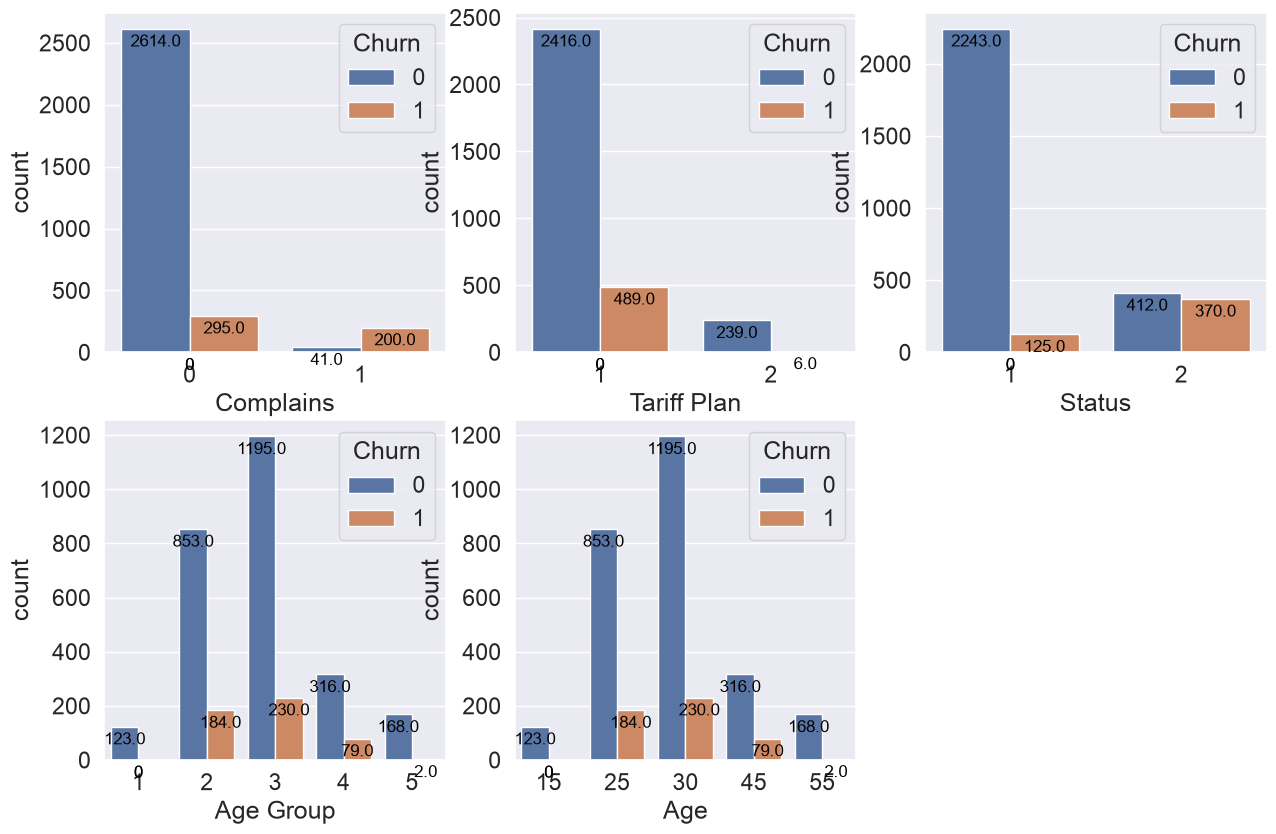

In [424]:
#Generate a graphical representation of each feature with the target variable
plt.figure(figsize=(15, 15))
sns.set(font_scale=1.5)

plt.subplot(331)
ax = sns.countplot(data=df, x='Complains', hue='Churn')
for p in ax.patches:
    ax.annotate(f'\n{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='top', fontsize=12, color='black', xytext=(0, 10), textcoords='offset points')

plt.subplot(332)
ax = sns.countplot(data=df, x='Tariff Plan', hue='Churn')
for p in ax.patches:
    ax.annotate(f'\n{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='top', fontsize=12, color='black', xytext=(0, 10), textcoords='offset points')

plt.subplot(333)
ax = sns.countplot(data=df, x='Status', hue='Churn')
for p in ax.patches:
    ax.annotate(f'\n{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='top', fontsize=12, color='black', xytext=(0, 10), textcoords='offset points')

plt.subplot(334)
ax = sns.countplot(data=df, x='Age Group', hue='Churn')
for p in ax.patches:
    ax.annotate(f'\n{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='top', fontsize=12, color='black', xytext=(0, 10), textcoords='offset points')

plt.subplot(335)
ax = sns.countplot(data=df, x='Age', hue='Churn')
for p in ax.patches:
    ax.annotate(f'\n{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='top', fontsize=12, color='black', xytext=(0, 10), textcoords='offset points')
plt.show()

## Summary of Bivariate analysis (0== Non churn, 1 == Churn)

- With regards to Complains (0 == No complaints, 1== Complaints), we can see that majority of customers who had no complaints (2614) kept using the services of the telecom company/ did not stop using the services of the company whiles only 295 of those without complaints churned along with 200 of people with complains, leaving 41 people with complaints still not churning.
- With regards to Tariff Plan as well, a greater proportion of customers on Pay as you go did not churn.
- Also with Status, returning / non churning users were more in both active and non-active users.
- People aged 30, 25 and 45 had the highest count of non churning users with customers aged 30 and 25 having the highest count of churners as well

## Univariate Analysis
The columns/ features analysed included Complains, Status, Tariff Plan, Age Group, Age, Call Failure, Charge Amount, Subscription Length, Churn etc.

/var/folders/q3/w36ytn292x36qmcvwkqrdt0w0000gn/T/ipykernel_77055/3879903467.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x="Tariff Plan", data=df, palette=sns.color_palette("husl", 8), saturation=15)
/var/folders/q3/w36ytn292x36qmcvwkqrdt0w0000gn/T/ipykernel_77055/3879903467.py:5: UserWarning: The palette list has more values (8) than needed (2), which may not be intended.
  ax = sns.countplot(x="Tariff Plan", data=df, palette=sns.color_palette("husl", 8), saturation=15)
/var/folders/q3/w36ytn292x36qmcvwkqrdt0w0000gn/T/ipykernel_77055/3879903467.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=0, ha='right', fontsize=15)


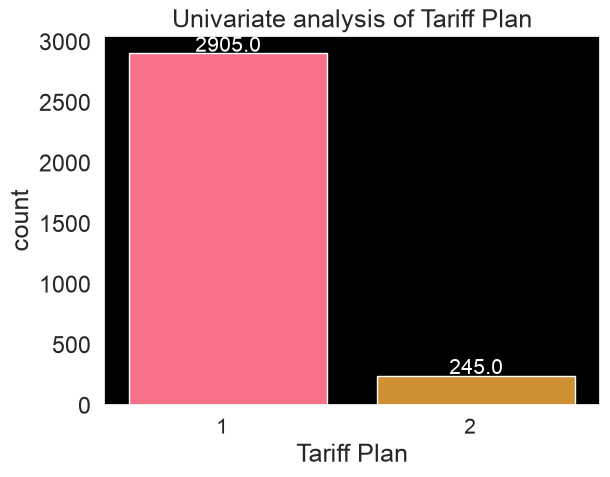

In [425]:
#Set the style to dark and background color to black
sns.set_style("dark", {"axes.facecolor": "black"})

#Plot countplot with specified palette
ax = sns.countplot(x="Tariff Plan", data=df, palette=sns.color_palette("husl", 8), saturation=15)

#Add count of the bars
for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='center', fontsize=15, color='white', xytext=(0, 5), textcoords='offset points', rotation=0)

#Rotate x-labels and reduce font size
ax.set_xticklabels(ax.get_xticklabels(), rotation=0, ha='right', fontsize=15)

#Show title
plt.title('Univariate analysis of Tariff Plan')

#Show the plot
plt.show()

/var/folders/q3/w36ytn292x36qmcvwkqrdt0w0000gn/T/ipykernel_77055/362691497.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x="Subscription  Length", data=df, palette=sns.color_palette("husl", 8), saturation=10)
/var/folders/q3/w36ytn292x36qmcvwkqrdt0w0000gn/T/ipykernel_77055/362691497.py:5: UserWarning: 
The palette list has fewer values (8) than needed (45) and will cycle, which may produce an uninterpretable plot.
  ax = sns.countplot(x="Subscription  Length", data=df, palette=sns.color_palette("husl", 8), saturation=10)
/var/folders/q3/w36ytn292x36qmcvwkqrdt0w0000gn/T/ipykernel_77055/362691497.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=90, ha='rig

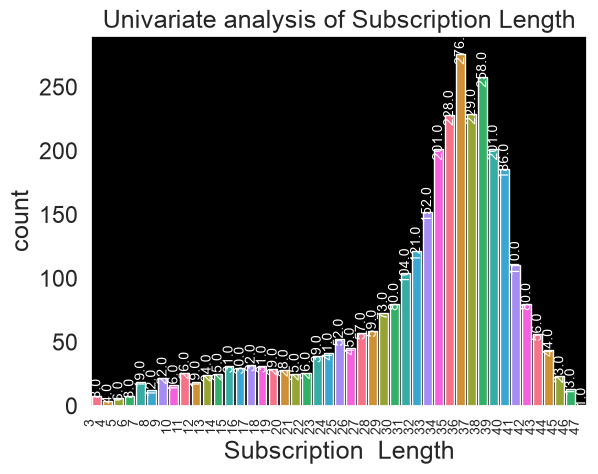

In [426]:
#Set the style to dark and background color to black
sns.set_style("dark", {"axes.facecolor": "black"})

#Plot countplot with specified palette
ax = sns.countplot(x="Subscription  Length", data=df, palette=sns.color_palette("husl", 8), saturation=10)

#Add count of the bars
for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='center', fontsize=10, color='white', xytext=(0, 5), textcoords='offset points', rotation=90)

#Show title
plt.title('Univariate analysis of Subscription Length')

#Rotate x-labels and reduce font size
ax.set_xticklabels(ax.get_xticklabels(), rotation=90, ha='right', fontsize=10)

#Show the plot
plt.show()

In [427]:
#Get the average subscription length
average_subscription_length = df["Subscription  Length"].mean()

#Print the average subscription length
print("Average Subscription Length:", round(average_subscription_length,2))

Average Subscription Length: 32.54


/var/folders/q3/w36ytn292x36qmcvwkqrdt0w0000gn/T/ipykernel_77055/367920602.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x="Charge  Amount", data=df, palette=sns.color_palette("husl", 8), saturation=10)
/var/folders/q3/w36ytn292x36qmcvwkqrdt0w0000gn/T/ipykernel_77055/367920602.py:5: UserWarning: 
The palette list has fewer values (8) than needed (11) and will cycle, which may produce an uninterpretable plot.
  ax = sns.countplot(x="Charge  Amount", data=df, palette=sns.color_palette("husl", 8), saturation=10)


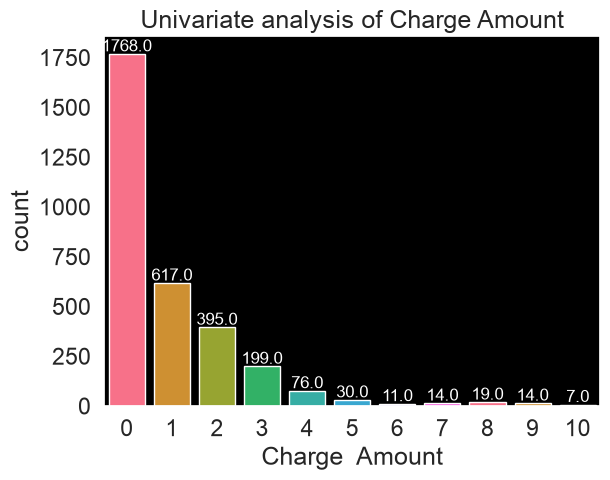

In [428]:
#Set the style to dark and background color to black
sns.set_style("dark", {"axes.facecolor": "black"})

#Plot countplot with specified palette
ax = sns.countplot(x="Charge  Amount", data=df, palette=sns.color_palette("husl", 8), saturation=10)

#Add count of the bars
for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='center', fontsize=12, color='white', xytext=(0, 5), textcoords='offset points')

#Show title
plt.title('Univariate analysis of Charge Amount')

#Show the plot
plt.show()

In [429]:
#Get the average charge amount
average_charge_amount = df["Charge  Amount"].mean()

#Print the average charge amount
print("Average Charge Amount:", round(average_charge_amount,2))

Average Charge Amount: 0.94


/var/folders/q3/w36ytn292x36qmcvwkqrdt0w0000gn/T/ipykernel_77055/2640357676.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x="Call  Failure", data=df, palette=sns.color_palette("husl", 8), saturation=10)
/var/folders/q3/w36ytn292x36qmcvwkqrdt0w0000gn/T/ipykernel_77055/2640357676.py:5: UserWarning: 
The palette list has fewer values (8) than needed (37) and will cycle, which may produce an uninterpretable plot.
  ax = sns.countplot(x="Call  Failure", data=df, palette=sns.color_palette("husl", 8), saturation=10)
/var/folders/q3/w36ytn292x36qmcvwkqrdt0w0000gn/T/ipykernel_77055/2640357676.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=90, ha='right', fontsi

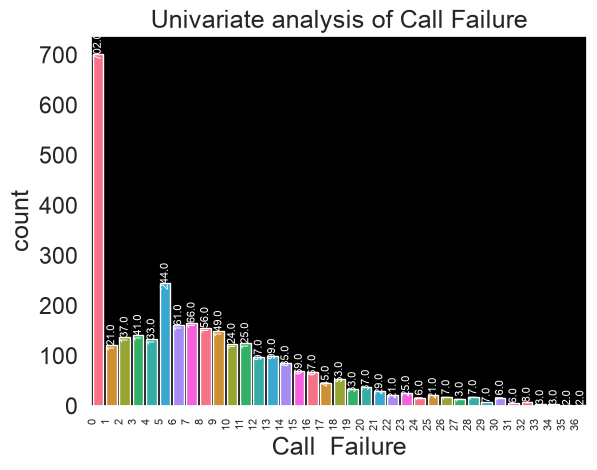

In [430]:
#Set the style to dark and background color to black
sns.set_style("dark", {"axes.facecolor": "black"})

#Plot countplot with specified palette
ax = sns.countplot(x="Call  Failure", data=df, palette=sns.color_palette("husl", 8), saturation=10)

#Add count of the bars
for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='center', fontsize=8, color='white', xytext=(0, 5), textcoords='offset points', rotation=90)

#Rotate x-labels and data labels by 90 degrees
plt.xticks(rotation=90)

#Show title
plt.title('Univariate analysis of Call Failure')

#Rotate x-labels and reduce font size
ax.set_xticklabels(ax.get_xticklabels(), rotation=90, ha='right', fontsize=8)

#Show the plot
plt.show()

In [431]:
#Get the average call failure
average_call_failure = df["Call  Failure"].mean()

#Print the average call failure
print("Average Call Failure:", round(average_call_failure,2))

Average Call Failure: 7.63


/var/folders/q3/w36ytn292x36qmcvwkqrdt0w0000gn/T/ipykernel_77055/3783718020.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x="Age", data=df, palette=sns.color_palette("husl", 8), saturation=10)
/var/folders/q3/w36ytn292x36qmcvwkqrdt0w0000gn/T/ipykernel_77055/3783718020.py:5: UserWarning: The palette list has more values (8) than needed (5), which may not be intended.
  ax = sns.countplot(x="Age", data=df, palette=sns.color_palette("husl", 8), saturation=10)


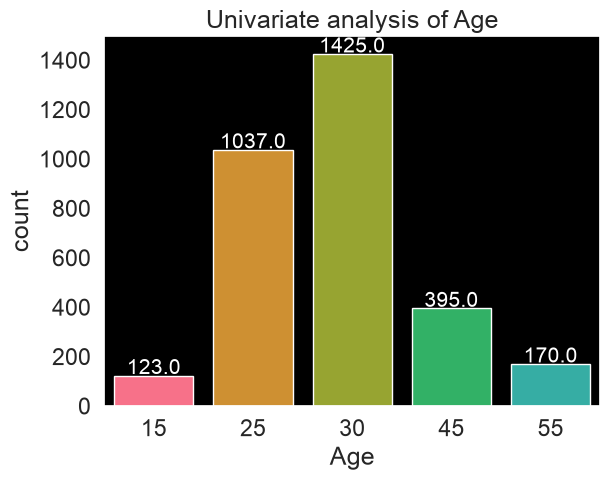

In [432]:
#Set the style to dark and background color to black
sns.set_style("dark", {"axes.facecolor": "black"})

#Plot countplot with specified palette
ax = sns.countplot(x="Age", data=df, palette=sns.color_palette("husl", 8), saturation=10)

#Add count of the bars
for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='center', fontsize=15, color='white', xytext=(0, 5), textcoords='offset points')

#Show title
plt.title('Univariate analysis of Age')

#Show the plot
plt.show()

In [433]:
#Get the average age
average_age = df["Age"].mean()

#Print the average age
print("Average Age:", round(average_age,2))

Average Age: 31.0


/var/folders/q3/w36ytn292x36qmcvwkqrdt0w0000gn/T/ipykernel_77055/3795108627.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x="Complains", data=df, palette=sns.color_palette("husl", 8), saturation=10)
/var/folders/q3/w36ytn292x36qmcvwkqrdt0w0000gn/T/ipykernel_77055/3795108627.py:5: UserWarning: The palette list has more values (8) than needed (2), which may not be intended.
  ax = sns.countplot(x="Complains", data=df, palette=sns.color_palette("husl", 8), saturation=10)


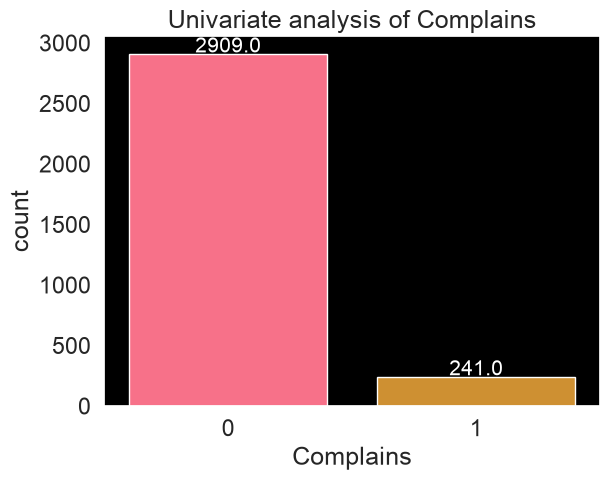

In [434]:
#Set the style to dark and background color to black
sns.set_style("dark", {"axes.facecolor": "black"})

#Plot countplot with specified palette
ax = sns.countplot(x="Complains", data=df, palette=sns.color_palette("husl", 8), saturation=10)

#Add count of the bars
for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='center', fontsize=15, color='white', xytext=(0, 5), textcoords='offset points')

#Show title
plt.title('Univariate analysis of Complains')

#Show the plot
plt.show()

/var/folders/q3/w36ytn292x36qmcvwkqrdt0w0000gn/T/ipykernel_77055/1796492725.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x="Status", data=df, palette=sns.color_palette("husl", 8), saturation=10)
/var/folders/q3/w36ytn292x36qmcvwkqrdt0w0000gn/T/ipykernel_77055/1796492725.py:5: UserWarning: The palette list has more values (8) than needed (2), which may not be intended.
  ax = sns.countplot(x="Status", data=df, palette=sns.color_palette("husl", 8), saturation=10)


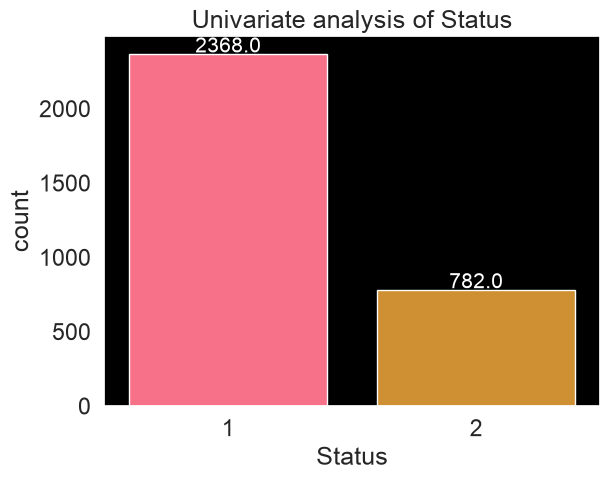

In [435]:
#Set the style to dark and background color to black
sns.set_style("dark", {"axes.facecolor": "black"})

#Plot countplot with specified palette
ax = sns.countplot(x="Status", data=df, palette=sns.color_palette("husl", 8), saturation=10)

#Add count of the bars
for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='center', fontsize=15, color='white', xytext=(0, 5), textcoords='offset points')

#Show title
plt.title('Univariate analysis of Status')

#Show the plot
plt.show()

/var/folders/q3/w36ytn292x36qmcvwkqrdt0w0000gn/T/ipykernel_77055/2032284880.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x="Age Group", data=df, palette=sns.color_palette("husl", 8), saturation=10)
/var/folders/q3/w36ytn292x36qmcvwkqrdt0w0000gn/T/ipykernel_77055/2032284880.py:5: UserWarning: The palette list has more values (8) than needed (5), which may not be intended.
  ax = sns.countplot(x="Age Group", data=df, palette=sns.color_palette("husl", 8), saturation=10)


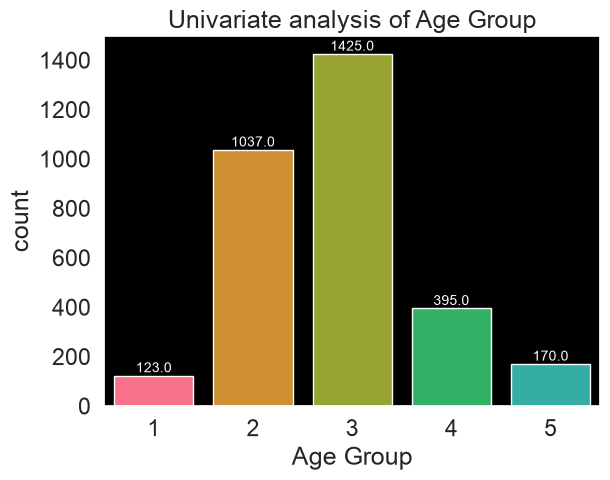

In [436]:
#Set the style to dark and background color to black
sns.set_style("dark", {"axes.facecolor": "black"})

#Plot countplot with specified palette
ax = sns.countplot(x="Age Group", data=df, palette=sns.color_palette("husl", 8), saturation=10)

#Add count of the bars
for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='center', fontsize=10, color='white', xytext=(0, 5), textcoords='offset points')

#Show title
plt.title('Univariate analysis of Age Group')

#Show the plot
plt.show()

In [437]:
#Get the average age Group
average_age_group = df["Age Group"].mean()

#Print the average age group
print("Average Age Group:", round(average_age_group,2))

Average Age Group: 2.83


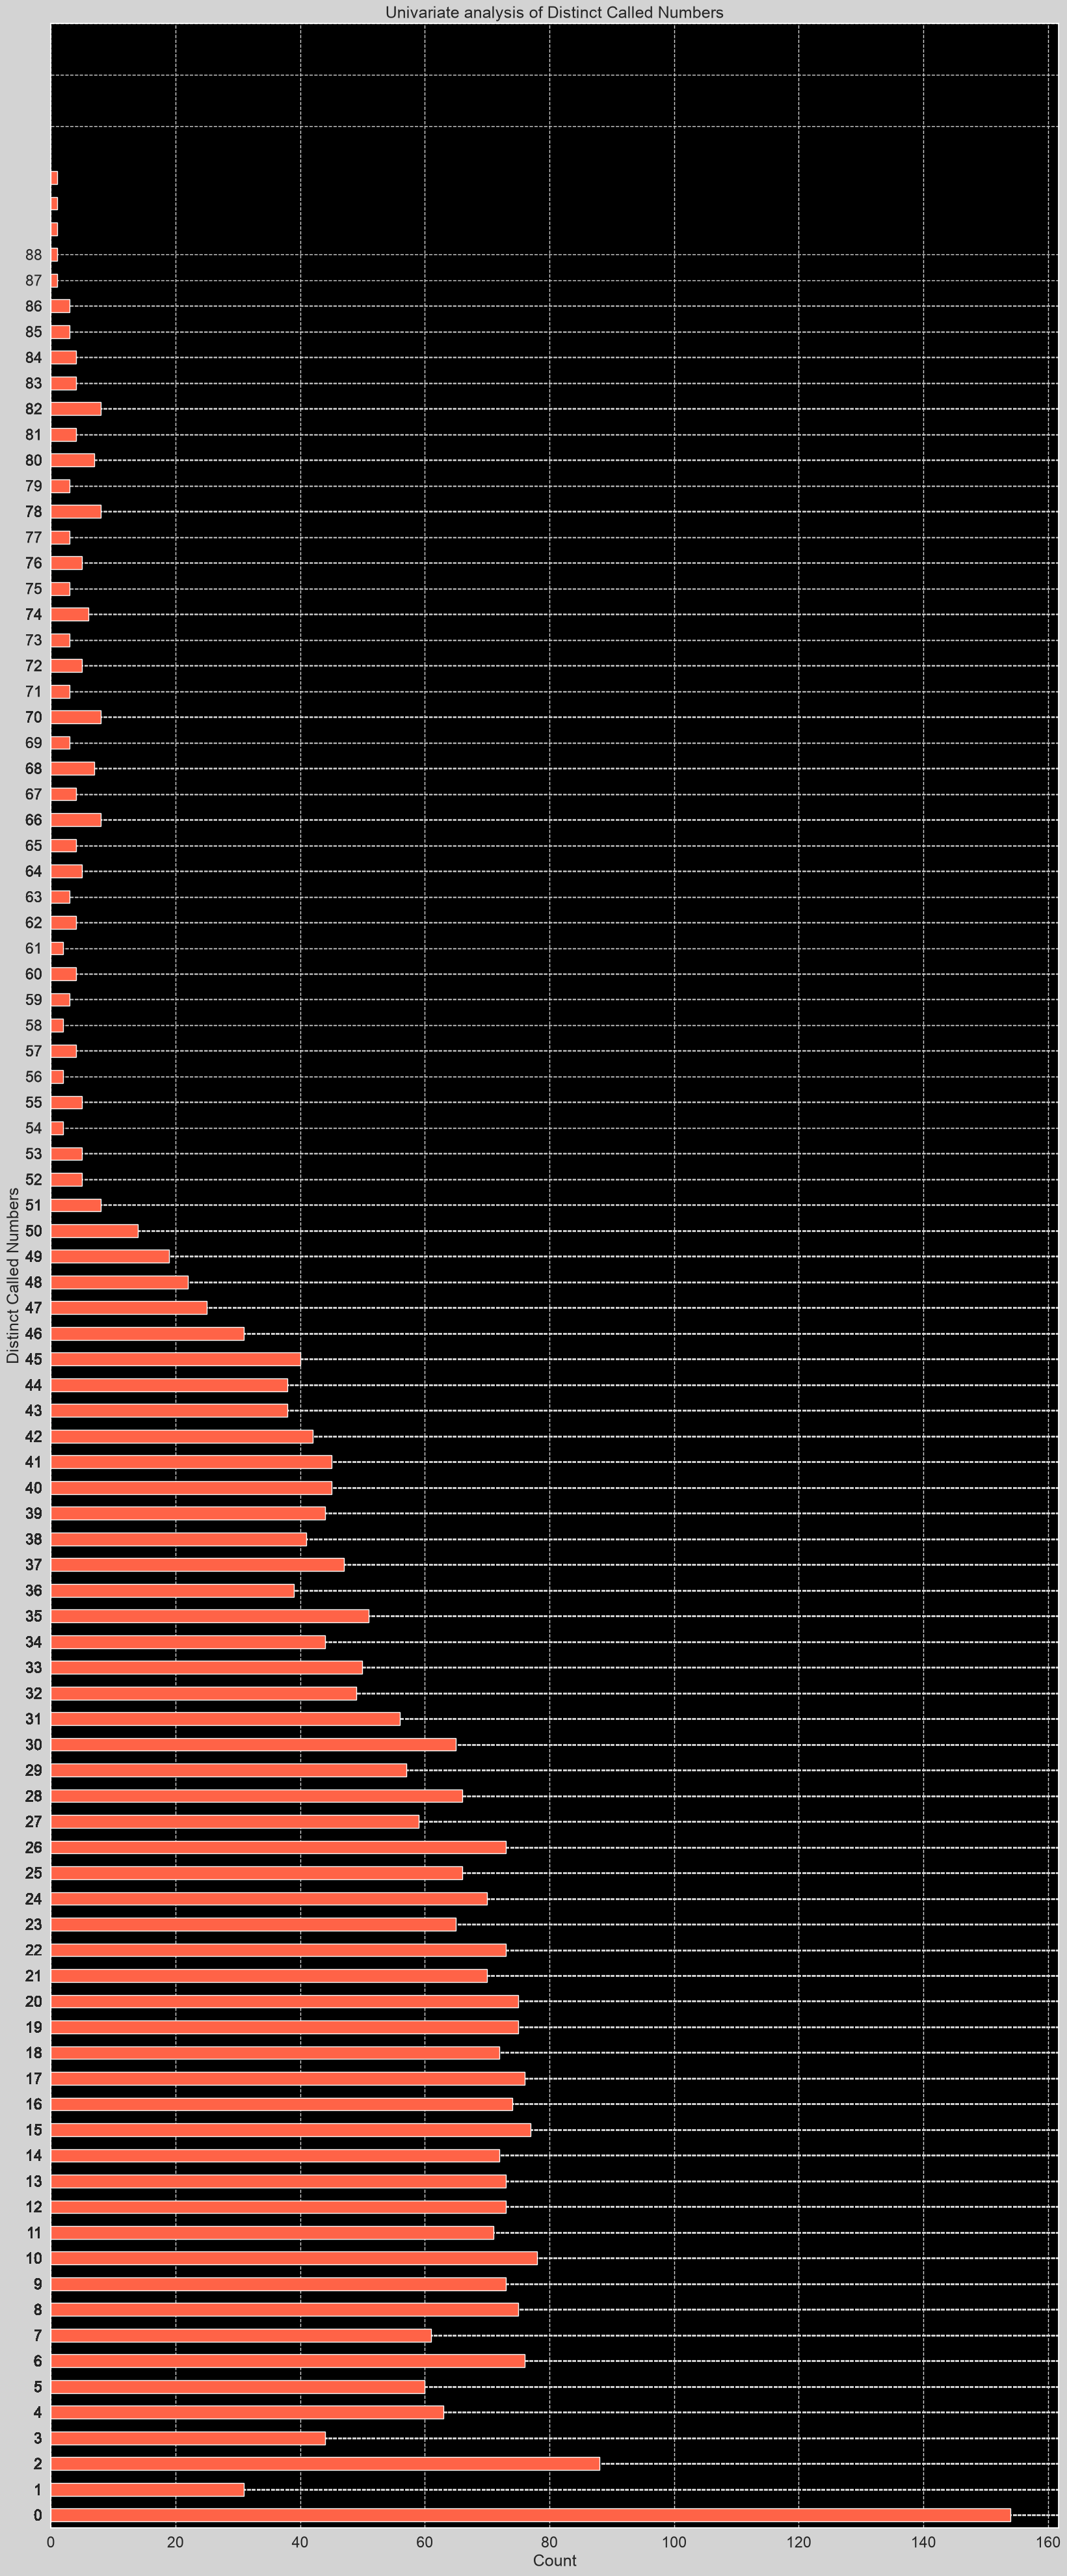

In [438]:
fig, ax =plt.subplots(facecolor = 'lightgrey', figsize=(20,50))
df['Distinct Called Numbers'].value_counts().sort_index().plot(kind='barh', ax=ax, color= 'tomato')
ax.set_ylabel('Distinct Called Numbers')
ax.set_xlabel('Count')
ax.set_title("Univariate analysis of Distinct Called Numbers")
ax.grid(axis="x", ls="--", color="lightgray")
ax.grid(axis="y", ls="--", color = "lightgray")
plt.xticks(rotation = 0)

yticks = df['Distinct Called Numbers']
ax.set_yticks(yticks)
plt.show()

In [439]:
#Get the average distinct called numbers
average_distinct_called_numbers = df["Distinct Called Numbers"].mean()

#Print the average distinct called numbers
print("Average Distinct Called Numbers:", round(average_distinct_called_numbers,2))

Average Distinct Called Numbers: 23.51


## Summary of Univariate Analysis

- More customers preferred to be on Pay as you go plan as compared to contractual  tariff plan.
- Number of Call Failures being 0 was the highest (no call failure) thus probably influencing the high number of non churners.
- Most customers were aged 30 followed by 25.
- Customers with no complaints were highest.
- Count of Active Customers were also more than Non- Active ones.

- <b>Tariff Plan, Complains and Status also contained imbalanced data samples which might affect the Machine Learning Algorithm.

## Checking for Outliers

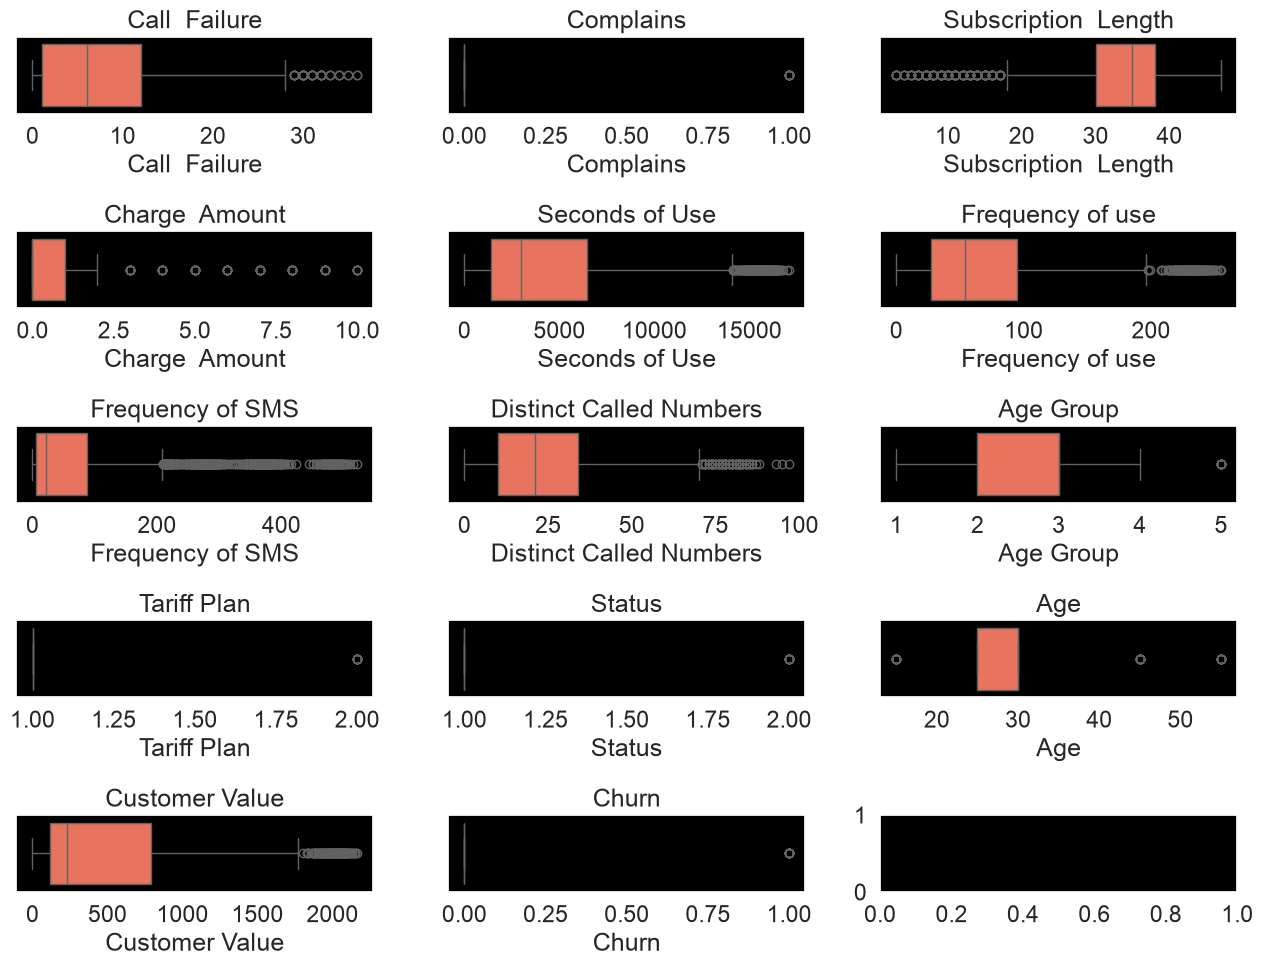

In [440]:
columns = df.columns
inputs = list(columns)

#Determine the number of logging curves
num_inputs = len(inputs)

#Create a figure with 1 row, and num_inputs long
fig, axs = plt.subplots(5, 3, figsize=(13,10))

#create a separate box plot
for i, (ax, curve) in enumerate(zip(axs.flat, inputs)):
    sns.boxplot(x=df[curve], ax=ax, color = 'tomato') 
    ax.set_title(inputs[i])
    ax.set_ylabel('')

plt.tight_layout()
plt.show()

The charts shows data distribution for dataframe features. For features like Call Failure, Subscription Lenght, Charge Amount, Seconds of Use, Frecuency of Use, Frecuency of SMS, Distinct Called Numbers, Age, Customer Value, the values are either skewed to the left or right, and there is presence of outliers.

<b>CHECKING FOR MISSING/NULL VALUES

In [441]:
df.isnull().sum()

Call  Failure              0
Complains                  0
Subscription  Length       0
Charge  Amount             0
Seconds of Use             0
Frequency of use           0
Frequency of SMS           0
Distinct Called Numbers    0
Age Group                  0
Tariff Plan                0
Status                     0
Age                        0
Customer Value             0
Churn                      0
dtype: int64

Based on this, there are no missing values in the dataset hence not so much pre-processing to be done

<b>FINDING DUPLICATES

# Here, we want to see every copy of the duplicates and not just the extras
df.duplicated() only flags the 2nd, 3rd and later copies. keep=False flags the first copy as well, so you see each full group:

In [442]:
dups = df[df.duplicated(keep=False)]
print(f"{len(dups)} rows are involved in duplication")
print(f"{df.duplicated().sum()} are extra copies")

# sort so identical rows sit next to each other
dups.sort_values(list(df.columns)).head(20)

465 rows are involved in duplication
300 are extra copies


,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
2049,0,0,7,0,1182,13,0,5,2,1,1,25,53.775,1
2099,0,0,7,0,1182,13,0,5,2,1,1,25,53.775,1
1098,0,0,7,0,4085,34,208,8,3,1,1,30,996.760,0
2048,0,0,7,0,4085,34,208,8,3,1,1,30,996.760,0
2098,0,0,7,0,4085,34,208,8,3,1,1,30,996.760,0
1094,0,0,16,0,1390,20,21,12,2,1,1,25,157.950,0
2044,0,0,16,0,1390,20,21,12,2,1,1,25,157.950,0
2094,0,0,16,0,1390,20,21,12,2,1,1,25,157.950,0
1691,0,0,23,0,0,0,0,0,4,1,2,45,0.000,0
1991,0,0,23,0,0,0,0,0,4,1,2,45,0.000,0


# How many times does each row repeat itself

In [443]:
group_sizes = dups.groupby(list(df.columns)).size().sort_values(ascending=False)
print(group_sizes.value_counts())   # e.g. "2 → 280 groups" means mostly pairs
group_sizes.head(10)

3    113
2     44
4      4
6      2
5      2
Name: count, dtype: int64


Call  Failure  Complains  Subscription  Length  Charge  Amount  Seconds of Use  Frequency of use  Frequency of SMS  Distinct Called Numbers  Age Group  Tariff Plan  Status  Age  Customer Value  Churn
0              0          37                    0               0               0                 0                 0                        2          1            2       25   0.000           0        6
                          35                    0               0               0                 0                 0                        2          1            2       25   0.000           1        6
                          37                    0               0               0                 0                 0                        2          1            2       25   0.000           1        5
                          34                    0               0               0                 0                 0                        5          1            1       55   0.000  

So here we can see that 3 had the highest but does not really point out anything in specific

# Where do they sit in the file?

In [444]:
dup_idx = df[df.duplicated(keep=False)].index
print(dup_idx[:50].tolist())

# for each duplicate, how far away is the original?
first = df.drop_duplicates(keep='first')
merged = df.reset_index().merge(first.reset_index(), on=list(df.columns), suffixes=('', '_orig'))
gaps = merged[merged['index'] != merged['index_orig']]
(gaps['index'] - gaps['index_orig']).describe()

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 13, 14, 15, 17, 18, 19, 20, 21, 22, 24, 25, 26, 28, 29, 30, 32, 34, 35, 36, 37, 38, 39, 40, 42, 43, 44, 48, 118, 128, 132, 201, 218, 301, 318, 331, 401, 428, 518]


count     300.000000
mean      911.930000
std       313.098356
min        50.000000
25%       950.000000
50%       950.000000
75%      1000.000000
max      1950.000000
dtype: float64

# Are they "empty" customers?\\\
Because the dataset has no customer ID, most features having the same rrecords would most likely seem identical and look like a duplicate instead of real and separate customers. so with this project, we atre going to vbe treating them as the same customers hence duplicates

In [445]:
dups[['Seconds of Use', 'Frequency of use', 'Frequency of SMS', 'Status', 'Churn']].describe()
(dups['Seconds of Use'] == 0).mean()

np.float64(0.15053763440860216)

In [446]:
features = [c for c in df.columns if c != 'Churn']
conflict = df.groupby(features)['Churn'].nunique()
print((conflict > 1).sum(), "feature-identical groups with different Churn labels")
print(df[df.duplicated(keep=False)]['Churn'].value_counts(normalize=True))

14 feature-identical groups with different Churn labels
Churn
0    0.825806
1    0.174194
Name: proportion, dtype: float64


In [447]:
df = df.drop_duplicates().reset_index(drop=True)

In [448]:
duplicates = df.duplicated().sum()
duplicates

np.int64(0)

## Check and remove highly correlated independent variables

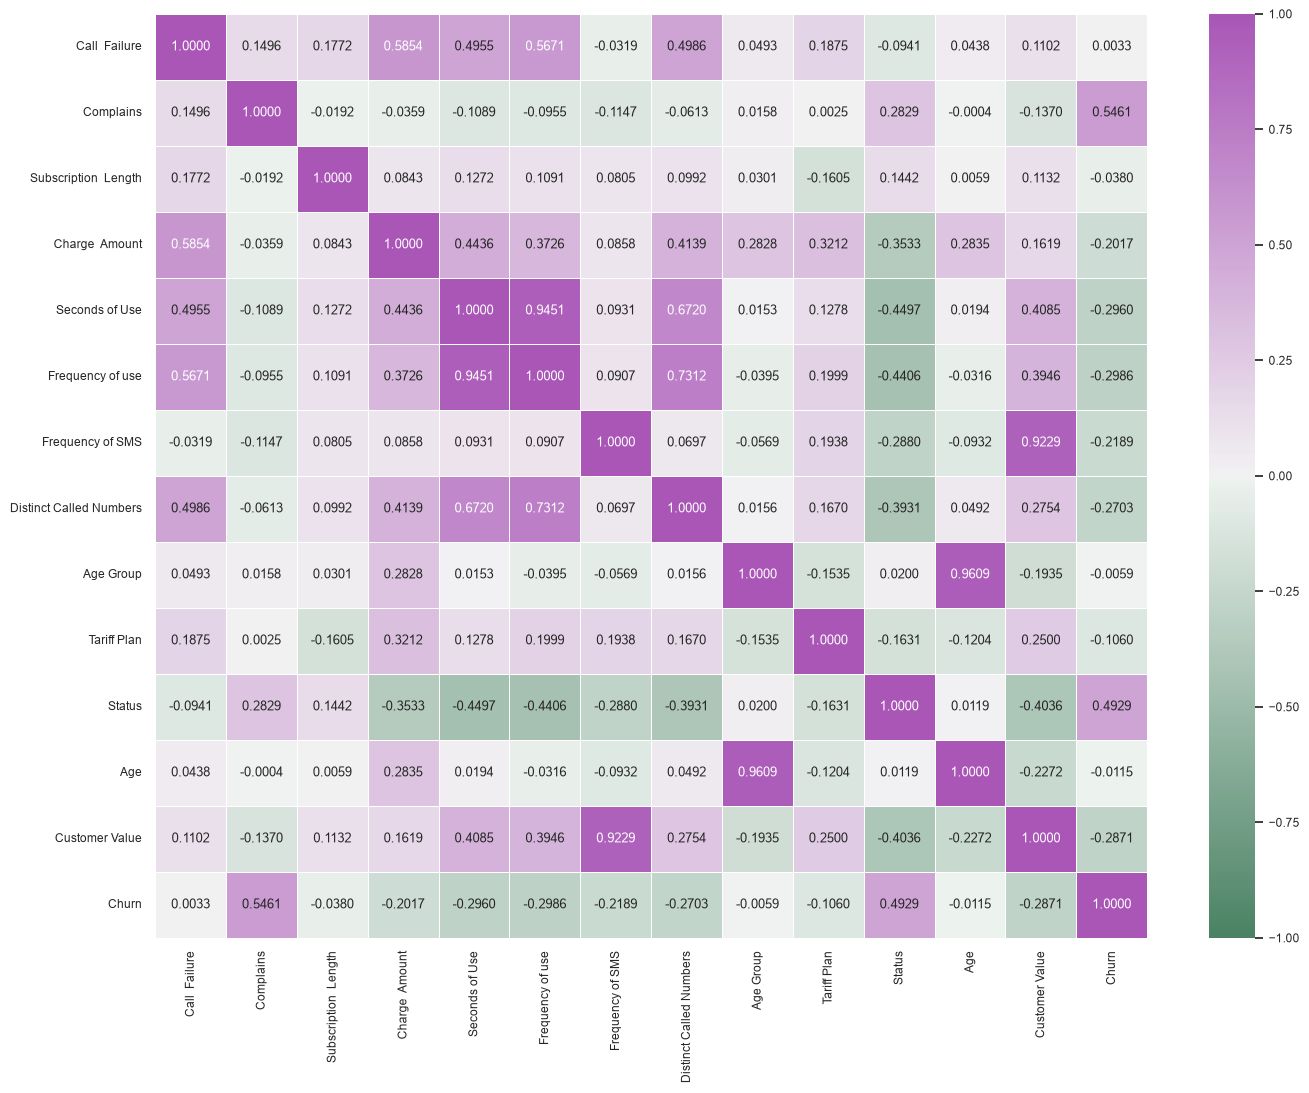

In [449]:
corr = df.corr()

# correlation matrix
sns.set(font_scale=0.8)
plt.figure(figsize=(16,12))
sns.heatmap(corr, annot=True, fmt=".4f",vmin=-1, vmax=1, linewidths=.5, cmap = sns.diverging_palette(145, 300, s=60, as_cmap=True))

#plt.yticks(rotation=0)
plt.show()

In [450]:
corr = df.corr()

# Print the correlation of the features
features = corr.columns.tolist()
for i, feature in enumerate(features):
    for j in range(i+1, len(features)):
        correlation_value = corr.iloc[i, j]
        print(f"{feature}-{features[j]}: {correlation_value:.4f}")

Call  Failure-Complains: 0.1496
Call  Failure-Subscription  Length: 0.1772
Call  Failure-Charge  Amount: 0.5854
Call  Failure-Seconds of Use: 0.4955
Call  Failure-Frequency of use: 0.5671
Call  Failure-Frequency of SMS: -0.0319
Call  Failure-Distinct Called Numbers: 0.4986
Call  Failure-Age Group: 0.0493
Call  Failure-Tariff Plan: 0.1875
Call  Failure-Status: -0.0941
Call  Failure-Age: 0.0438
Call  Failure-Customer Value: 0.1102
Call  Failure-Churn: 0.0033
Complains-Subscription  Length: -0.0192
Complains-Charge  Amount: -0.0359
Complains-Seconds of Use: -0.1089
Complains-Frequency of use: -0.0955
Complains-Frequency of SMS: -0.1147
Complains-Distinct Called Numbers: -0.0613
Complains-Age Group: 0.0158
Complains-Tariff Plan: 0.0025
Complains-Status: 0.2829
Complains-Age: -0.0004
Complains-Customer Value: -0.1370
Complains-Churn: 0.5461
Subscription  Length-Charge  Amount: 0.0843
Subscription  Length-Seconds of Use: 0.1272
Subscription  Length-Frequency of use: 0.1091
Subscription  Leng

<Axes: title={'center': 'Comparing Churn with other features'}>

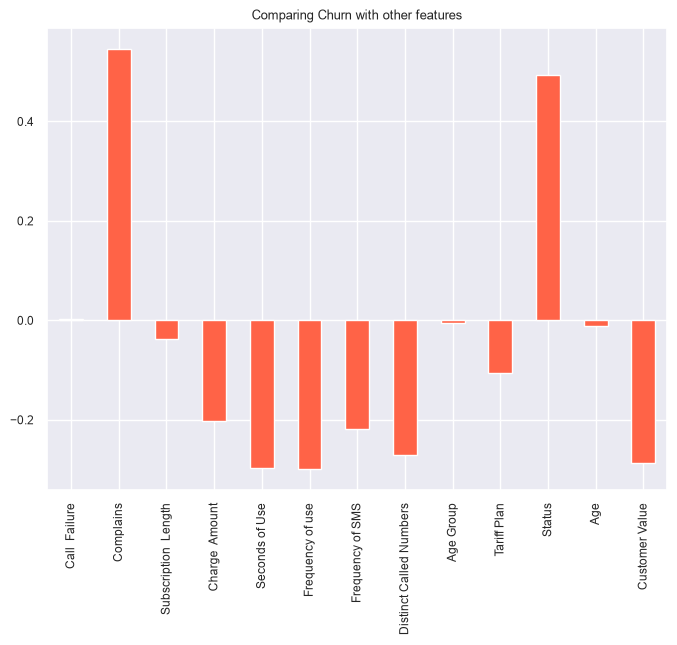

In [451]:
#Checking for feature importance using corr
df.drop(columns = 'Churn').corrwith(df.Churn).plot(kind='bar', figsize=(8, 6), color='tomato', title="Comparing Churn with other features")

In [452]:
#Since age and Age Group are highly correlated,drop Age because len(Age)==len(Age Group) and Age Group was defined hence we know what it entails
df=df.drop(columns=["Age"])
#Drop Frequency of Use. Although it is highly correlated with Seconds of Use, it has a much lower correlation with Churn compared to Seconds of Use
df=df.drop(columns=['Frequency of use'])
#drop Frequency of SMS as it is highly correlated with Customer Value
df=df.drop(columns=['Frequency of SMS'])

In [453]:
df

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Distinct Called Numbers,Age Group,Tariff Plan,Status,Customer Value,Churn
0,8,0,38,0,4370,17,3,1,1,197.640,0
1,0,0,39,0,318,4,2,1,2,46.035,0
2,10,0,37,0,2453,24,3,1,1,1536.520,0
3,10,0,38,0,4198,35,1,1,1,240.020,0
4,3,0,38,0,2393,33,1,1,1,145.805,0
...,...,...,...,...,...,...,...,...,...,...,...
2845,17,0,17,1,9237,42,5,1,1,261.210,0
2846,13,0,18,4,3157,21,3,1,1,280.320,0
2847,8,1,11,2,1792,9,3,1,1,100.680,1
2848,26,0,38,9,10740,44,5,2,1,174.585,0


In [454]:
#Getting the upper limit
import numpy as np

upper_limit = np.max(df)
upper_limit

np.float64(17090.0)

###### Create Correlation Matrix after removal

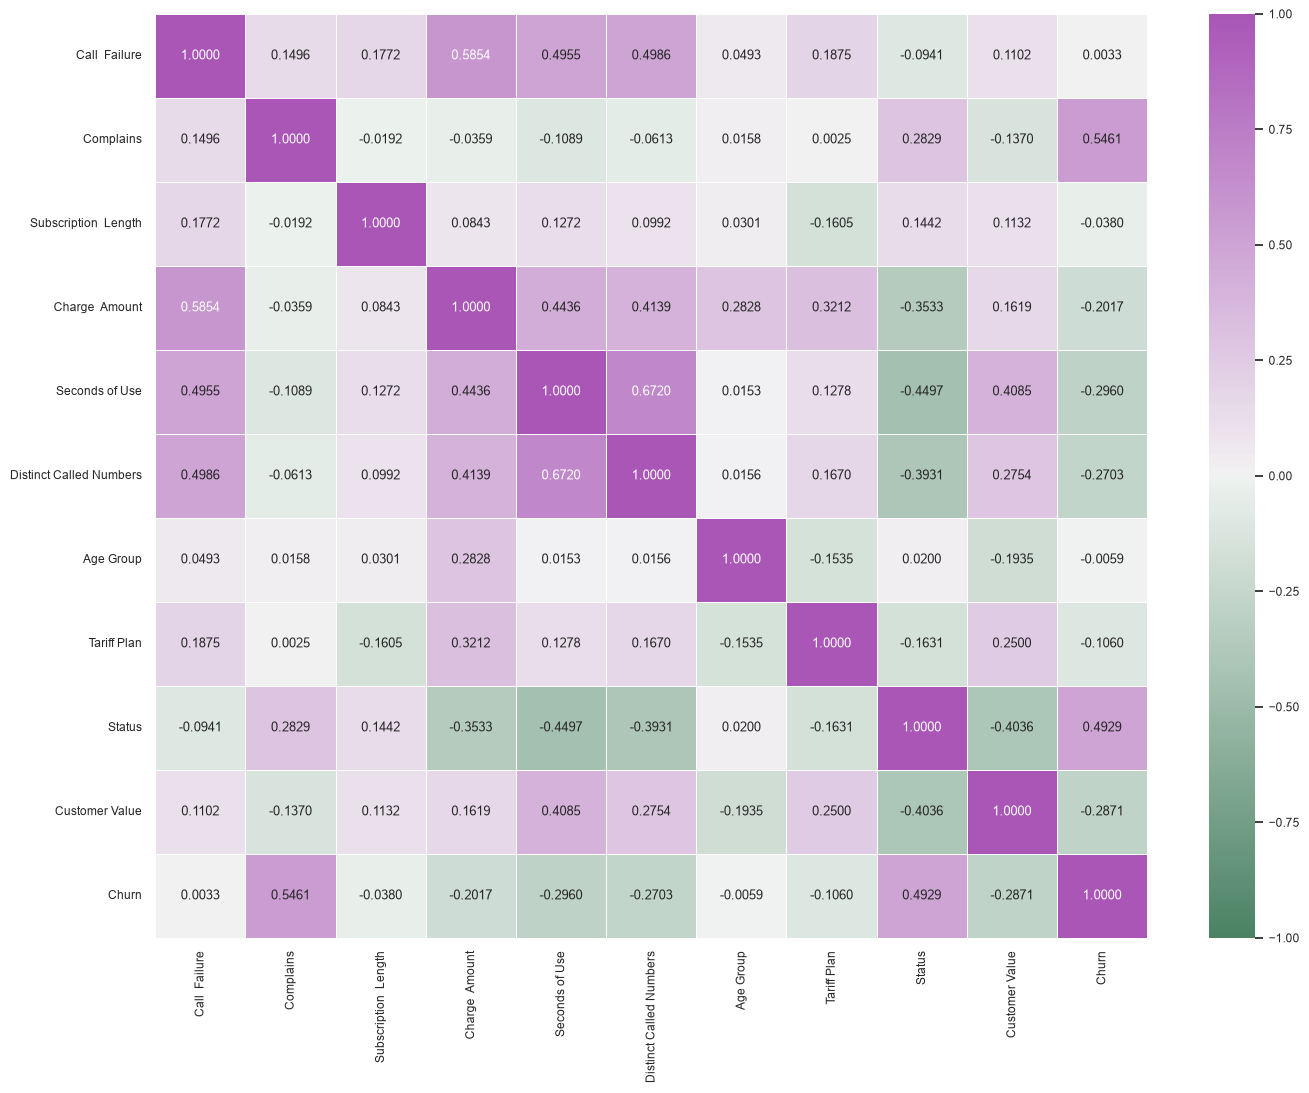

In [455]:
corr = df.corr()

# correlation matrix
sns.set(font_scale=0.8)
plt.figure(figsize=(16,12))
sns.heatmap(corr, annot=True, fmt=".4f",vmin=-1, vmax=1, linewidths=.5, cmap = sns.diverging_palette(145, 300, s=60, as_cmap=True))

#plt.yticks(rotation=0)
plt.show()

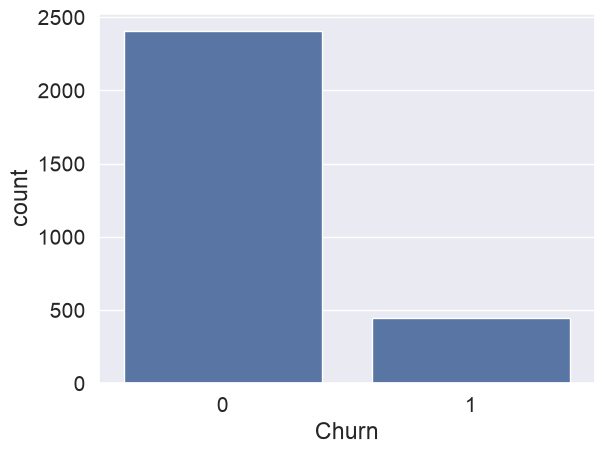

In [456]:
sns.set(font_scale=1.4) 
sns.countplot(df,x=df['Churn'])
plt.savefig("Imbalanced Target.png")

In [457]:
df['Churn'].value_counts()

Churn
0    2404
1     446
Name: count, dtype: int64

<h1>Imbalanced Dataset:

In [458]:
#Get the count of class 1 (churn)
count_of_churn = len(df[df['Churn']==1])

#Get the count of class 2 (non churn)
count_of_non_churn = len(df[df['Churn']==0])

#Get the percentage of churn and non churn
percentage_of_non_churn = count_of_non_churn/(count_of_non_churn+count_of_churn)
print(f"percentage of non churn is: {round((percentage_of_non_churn*100),2)}")
percentage_of_churn = count_of_churn/(count_of_churn+count_of_non_churn)
print(f"percentage of churn is: {round((percentage_of_churn*100),2)}")

percentage of non churn is: 84.35
percentage of churn is: 15.65


There is imbalance within the classes, and the ratio of non-churning customers to churning customer instances is 84:~16.

<h2> Split the data into X and y

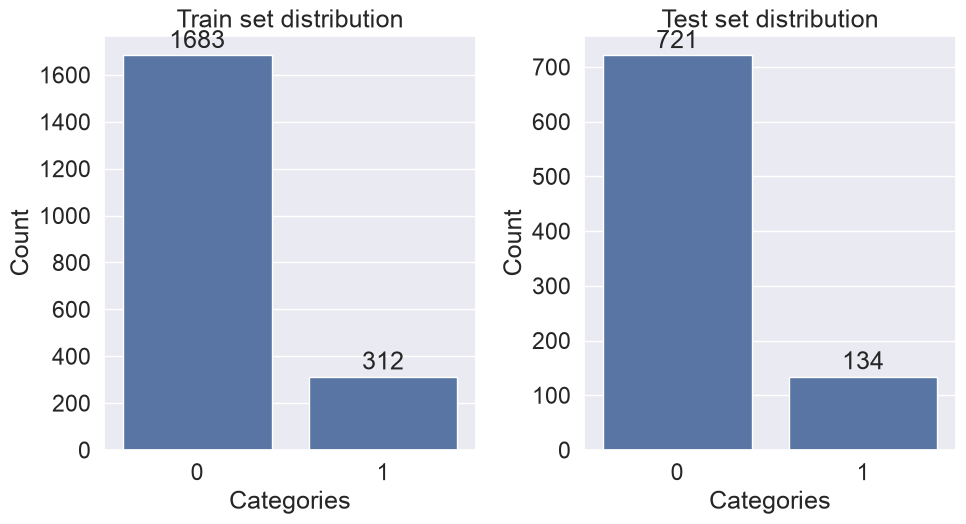

Training Set sample size (1995, 10)
Testing Set sample size (855, 10)


In [459]:
#Split data into X and y
X = df.drop(columns = ['Churn'])
y = df['Churn']

#Split the shuffled dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.3, random_state=42)

plt.figure(figsize=(10, 10))
sns.set(font_scale=1.5)

#Plotting the train set distribution
plt.subplot(221)
ax = sns.countplot(x=y_train)
ax.set_title('Train set distribution')
ax.set_xlabel('Categories')
ax.set_ylabel('Count')
for p in ax.patches:
    ax.annotate(format(p.get_height(), '.0f'), 
                   (p.get_x() + p.get_width() / 2., p.get_height()), 
                   ha = 'center', va = 'center', 
                   xytext = (0, 10), 
                   textcoords = 'offset points')

#Plotting the test set distribution
plt.subplot(222)
ax = sns.countplot(x=y_test)
ax.set_title('Test set distribution')
ax.set_xlabel('Categories')
ax.set_ylabel('Count')
for p in ax.patches:
    ax.annotate(format(p.get_height(), '.0f'), 
                   (p.get_x() + p.get_width() / 2., p.get_height()), 
                   ha = 'center', va = 'center', 
                   xytext = (0, 10), 
                   textcoords = 'offset points')

plt.tight_layout()
plt.show()

print(f'Training Set sample size {X_train.shape}')
print(f'Testing Set sample size {X_test.shape}')

In [460]:
#Getting X features
for i in X:
    print(i,end=',')

Call  Failure,Complains,Subscription  Length,Charge  Amount,Seconds of Use,Distinct Called Numbers,Age Group,Tariff Plan,Status,Customer Value,

## Check model performance with imbalanced dataset before normalizing and resampling

## LOGISTIC REGRESSION

In [461]:
#Initializing and training the logistic regression model on the imbalanced dataset
lr = LogisticRegression()

#Training the model on the imbalanced dataset
lr.fit(X_train, y_train)

#Predicting on the imbalanced test set
y_pred_imb = lr.predict(X_test)

#Evaluating the model on the imbalanced set
accuracy_imb = accuracy_score(y_test, y_pred_imb)
print(f'Accuracy on imbalanced Train Set: {round(lr.score(X_train, y_train)*100,2)}%')
print(f'Accuracy on imbalanced Test Set: {round(lr.score(X_test, y_test)*100,2)}%')

Accuracy on imbalanced Train Set: 88.12%
Accuracy on imbalanced Test Set: 87.37%


/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


##### Classification Report

In [462]:
#Print classification report
print(classification_report(y_test, y_pred_imb))

              precision    recall  f1-score   support

           0       0.89      0.97      0.93       721
           1       0.67      0.38      0.49       134

    accuracy                           0.87       855
   macro avg       0.78      0.67      0.71       855
weighted avg       0.86      0.87      0.86       855



## KNN

In [463]:
#Model definition and training
knn_model = KNeighborsClassifier()
knn_model.fit(X_train, y_train)

#calculate model accuracy with difference values of k/ determining no of K
accuracy_knn_imb = np.zeros(15)
for i in range(1,16):
    
    #train model and predict
    knn_model = KNeighborsClassifier(n_neighbors=i).fit(X_train, y_train)
    ypredicting_imb = knn_model.predict(X_test)
    accuracy_knn_imb[i-1] = metrics.accuracy_score(y_test, ypredicting_imb)
    
#print accuracies
accuracy_knn_imb    

array([0.82807018, 0.84561404, 0.82807018, 0.84327485, 0.83625731,
       0.84795322, 0.83508772, 0.84444444, 0.82573099, 0.84327485,
       0.83040936, 0.84093567, 0.83625731, 0.83976608, 0.83625731])

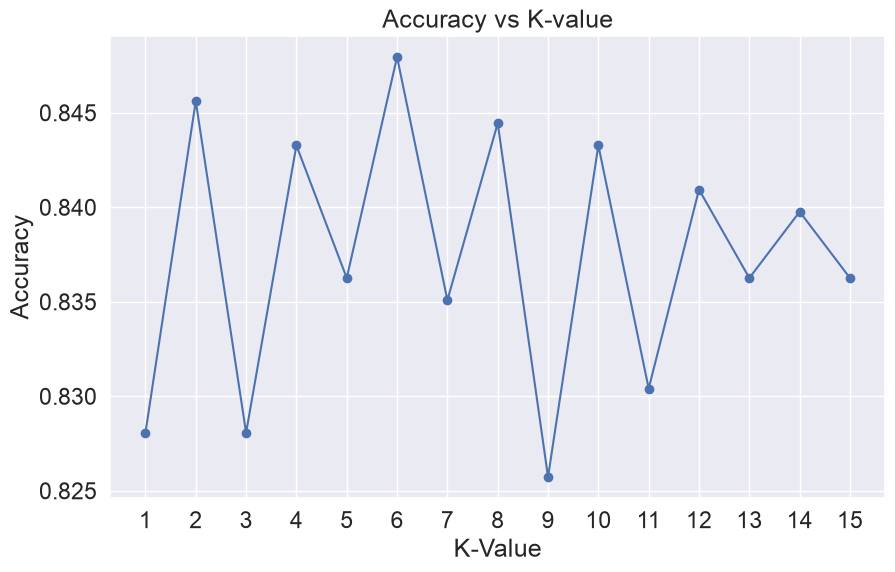

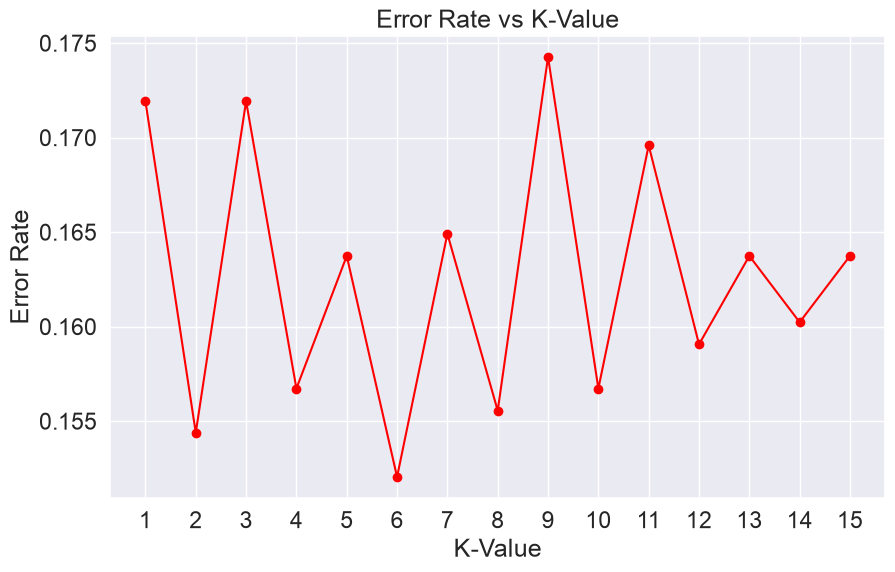

In [464]:
#plotting a graph to visualize
loc_imb = np.arange(1, 16, step=1.0)
plt.figure(figsize=(10, 6))
plt.plot(range(1, 16), accuracy_knn_imb, marker = 'o',linestyle='-')
plt.xticks(loc_imb)
plt.xlabel('K-Value')
plt.ylabel('Accuracy')
plt.title('Accuracy vs K-value')
plt.show()


#Calculate model accuracy with different values of k
accuracy_knn_imb = np.zeros(15)
error_rate_imb = []

for i in range(1, 16):
    #Train model and predict
    knn_model = KNeighborsClassifier(n_neighbors=i).fit(X_train, y_train)
    ypredicting_imb = knn_model.predict(X_test)
    accuracy_knn_imb[i - 1] = metrics.accuracy_score(y_test, ypredicting_imb)
    error_rate_imb.append(np.mean(ypredicting_imb != y_test))

#Plot the error rate vs K-Value
plt.figure(figsize=(10, 6))
plt.plot(range(1, 16), error_rate_imb, marker='o', linestyle='-', color='red')
plt.xticks(np.arange(1, 16, step=1))
plt.xlabel('K-Value')
plt.ylabel('Error Rate')
plt.title('Error Rate vs K-Value')
plt.show()


In [465]:
knn_model = KNeighborsClassifier(n_neighbors = 2)
knn_model.fit(X_train, y_train)

#PREDICTING
y_pred_knn_imb = knn_model.predict(X_test)

#ACCURACY
accuracy_knn_imb = accuracy_score(y_test, y_pred_knn_imb)
print(f'Train Accuracy on imbalanced dataset: {round(knn_model.score(X_train, y_train)*100,2)}%')
print(f'Test Accuracy on imbalanced dataset: {round(knn_model.score(X_test,y_test)*100,2)}%')

Train Accuracy on imbalanced dataset: 91.08%
Test Accuracy on imbalanced dataset: 84.56%


##### Classification Report

In [466]:
#Classification report
print(classification_report(y_test, y_pred_knn_imb))

              precision    recall  f1-score   support

           0       0.86      0.97      0.91       721
           1       0.52      0.17      0.26       134

    accuracy                           0.85       855
   macro avg       0.69      0.57      0.59       855
weighted avg       0.81      0.85      0.81       855



## NAIVE BAYES

In [467]:
#Initializing and training the Naive Bayes model on the imbalanced data
nb_model = GaussianNB()

#Training the model
nb_model.fit(X_train, y_train)

#Predicting on the imbalanced test set
y_pred_nb_imb = nb_model.predict(X_test)

#Evaluating the model
accuracy_nb_imb = accuracy_score(y_test, y_pred_nb_imb)
print(f'Accuracy on Imbalanced Train Set: {round(nb_model.score(X_train, y_train)*100,2)}%')
print(f'Accuracy on Imbalanced Test Set: {round(nb_model.score(X_test, y_test)*100,2)}%')

Accuracy on Imbalanced Train Set: 78.6%
Accuracy on Imbalanced Test Set: 77.89%


##### Classification Report

In [468]:
print(classification_report(y_test, y_pred_nb_imb))

              precision    recall  f1-score   support

           0       0.97      0.76      0.85       721
           1       0.41      0.89      0.56       134

    accuracy                           0.78       855
   macro avg       0.69      0.82      0.71       855
weighted avg       0.88      0.78      0.81       855



## DECISION TREE

In [469]:
#Initializing and training the Decision Tree model on the imbalanced data
dt_model = DecisionTreeClassifier()

#Training the model
dt_model.fit(X_train, y_train)

#Predicting on the imbalanced test set
y_pred_dt_imb = dt_model.predict(X_test)

#Evaluating the model
accuracy_dt_imb = accuracy_score(y_test, y_pred_dt_imb)
print(f'Accuracy on Imbalanced Train Set: {round(dt_model.score(X_train, y_train)*100,2)}%')
print(f'Accuracy on Imbalanced Test Set: {round(dt_model.score(X_test, y_test)*100,2)}%')

Accuracy on Imbalanced Train Set: 99.6%
Accuracy on Imbalanced Test Set: 92.75%


##### Classification Report

In [470]:
print(classification_report(y_test, y_pred_dt_imb))

              precision    recall  f1-score   support

           0       0.96      0.96      0.96       721
           1       0.77      0.76      0.77       134

    accuracy                           0.93       855
   macro avg       0.86      0.86      0.86       855
weighted avg       0.93      0.93      0.93       855



## RANDOM FOREST

In [471]:
#Initializing and training the Random Forest model on the imbalanced data
rf_model = RandomForestClassifier()

#Training the model
rf_model.fit(X_train, y_train)

#Predicting on the normalized test set
y_pred_rf_imb = rf_model.predict(X_test)

#Evaluating the model
accuracy_rf_imb = accuracy_score(y_test, y_pred_rf_imb)
print(f'Accuracy on Imbalanced Train Set: {round(rf_model.score(X_train, y_train)*100,2)}%')
print(f'Accuracy on Imbalanced Test Set: {round(rf_model.score(X_test, y_test)*100,2)}%')

Accuracy on Imbalanced Train Set: 99.6%
Accuracy on Imbalanced Test Set: 94.62%


##### Classification Report

In [472]:
print(classification_report(y_test, y_pred_rf_imb))

              precision    recall  f1-score   support

           0       0.96      0.98      0.97       721
           1       0.87      0.78      0.82       134

    accuracy                           0.95       855
   macro avg       0.91      0.88      0.89       855
weighted avg       0.94      0.95      0.94       855



## EXTREME GRADIENT BOOSTING 

In [473]:
#Initializing and training the Extreme Gradient Boosting model on the imbalanced data
gb_model = XGBClassifier()

#Training the model
gb_model.fit(X_train, y_train)

#Predicting on the imbalanced test set
y_pred_gb_imb = gb_model.predict(X_test)

#Evaluating the model
accuracy_gb_imb = accuracy_score(y_test, y_pred_gb_imb)
print(f'Accuracy on Imbalanced Train Set: {round(gb_model.score(X_train, y_train)*100,2)}%')
print(f'Accuracy on Imbalanced Test Set: {round(gb_model.score(X_test, y_test)*100,2)}%')

Accuracy on Imbalanced Train Set: 99.55%
Accuracy on Imbalanced Test Set: 94.62%


##### Classification Report

In [474]:
print(classification_report(y_test, y_pred_gb_imb))

              precision    recall  f1-score   support

           0       0.96      0.97      0.97       721
           1       0.84      0.81      0.82       134

    accuracy                           0.95       855
   macro avg       0.90      0.89      0.90       855
weighted avg       0.95      0.95      0.95       855



## SUPPORT VECTOR MACHINE

In [475]:
#Initializing and training the Support Vector Machine model on the imbalanced data
svm_model = SVC()

#Training the model
svm_model.fit(X_train, y_train)

#Predicting on the imbalanced test set
y_pred_svm_imb = svm_model.predict(X_test)

#Evaluating the model
accuracy_svm_imb = accuracy_score(y_test, y_pred_svm_imb)
print(f'Accuracy on Imbalanced Train Set: {round(svm_model.score(X_train, y_train)*100,2)}%')
print(f'Accuracy on Imbalanced Test Set: {round(svm_model.score(X_test, y_test)*100,2)}%')

Accuracy on Imbalanced Train Set: 84.36%
Accuracy on Imbalanced Test Set: 84.33%


##### Classification Report

In [476]:
print(classification_report(y_test, y_pred_svm_imb, zero_division=1))

              precision    recall  f1-score   support

           0       0.84      1.00      0.91       721
           1       1.00      0.00      0.00       134

    accuracy                           0.84       855
   macro avg       0.92      0.50      0.46       855
weighted avg       0.87      0.84      0.77       855



# Resampling using SMOTE and Normalising using MinMaxScaler

SMOTE (Synthetic Minority Over-sampling Technique) aims to address imbalanced class distributions by creating artificial samples for the minority class. It achieves this by creating synthetic instances that lie between existing minority class samples. To do this, SMOTE randomly selects instances from the minority class, identifies their k-nearest neighbors, and then generates synthetic samples along the line connecting these neighbors. This process helps to rebalance the class distribution and improve the performance of machine learning models.

## What SMOTE does to the class balance *(for illustration only)*
This cell applies SMOTE to a copy of the training set purely to show its effect.
The result is **not** used for training. The pipeline below re-applies SMOTE inside each cross-validation training fold, so validation and test data are never oversampled.

Training set before SMOTE: Counter({0: 1683, 1: 312})
Training set after SMOTE:  Counter({0: 1683, 1: 1683})
Test set (never resampled): Counter({0: 721, 1: 134})


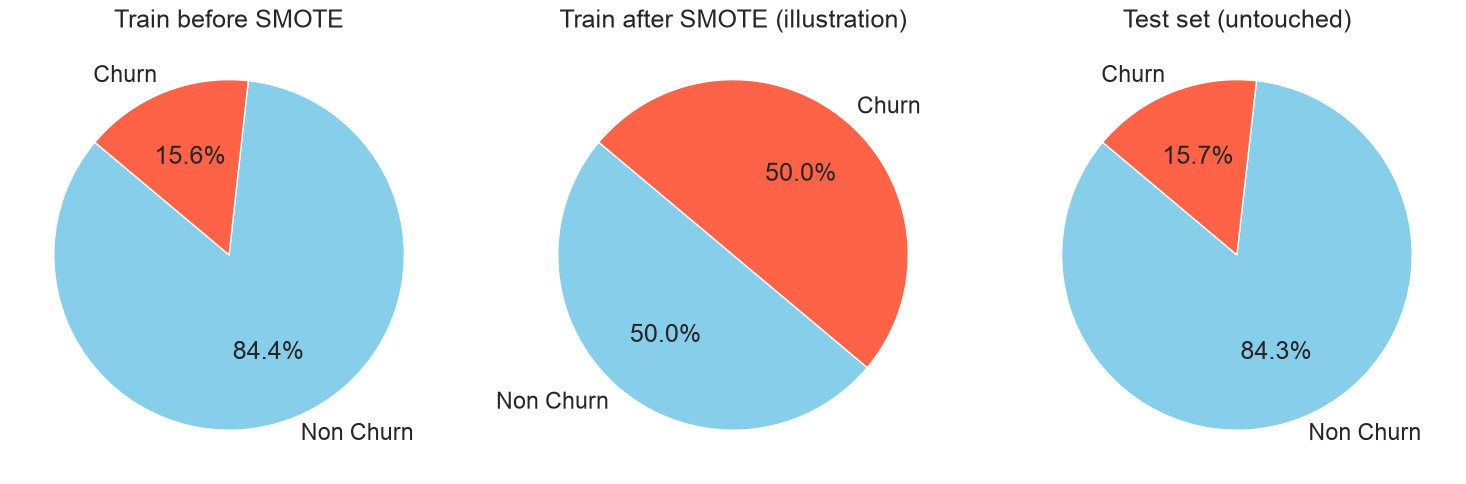

In [477]:
from collections import Counter
from imblearn.over_sampling import SMOTE

_, y_train_demo = SMOTE(random_state=42).fit_resample(X_train, y_train)
print(f'Training set before SMOTE: {Counter(y_train)}')
print(f'Training set after SMOTE:  {Counter(map(int, y_train_demo))}')
print(f'Test set (never resampled): {Counter(y_test)}')

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (title, data) in zip(axes, [('Train before SMOTE', y_train),
                                     ('Train after SMOTE (illustration)', y_train_demo),
                                     ('Test set (untouched)', y_test)]):
    counts = pd.Series(data).value_counts().sort_index()
    ax.pie(counts, labels=['Non Churn', 'Churn'], autopct='%1.1f%%',
           startangle=140, colors=['skyblue', 'tomato'])
    ax.set_title(title)
plt.tight_layout()
plt.show()

In [478]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
                             recall_score, f1_score, accuracy_score, classification_report)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def tune(name, model, param_grid):
    pipe = Pipeline([
        ('smote', SMOTE(random_state=42)),
        ('scaler', MinMaxScaler()),
        ('model', model),
    ])
    search = GridSearchCV(pipe, param_grid, cv=cv, scoring='average_precision', n_jobs=-1)
    search.fit(X_train, y_train)            # raw training data, NOT resampled beforehand
    best = search.best_estimator_           # refitted on all of X_train
    proba = best.predict_proba(X_test)[:, 1]
    pred = best.predict(X_test)

    print(f"===== {name} =====")
    print("Best params:", search.best_params_)
    print(classification_report(y_test, pred))

    return best, {
        'Algorithm': name,
        'CV PR-AUC': search.best_score_,
        'Test ROC-AUC': roc_auc_score(y_test, proba),
        'Test PR-AUC': average_precision_score(y_test, proba),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'Accuracy': accuracy_score(y_test, pred),
    }

## Tune all seven models

In [479]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

models = {
    'Logistic Regression': (LogisticRegression(max_iter=5000, solver='saga'),
        {'model__C': [0.01, 0.1, 1, 10], 'model__penalty': ['l1', 'l2']}),
    'KNN': (KNeighborsClassifier(),
        {'model__n_neighbors': [3, 5, 7, 9, 11, 15], 'model__weights': ['uniform', 'distance']}),
    'Naive Bayes': (GaussianNB(),
        {'model__var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6]}),
    'Decision Tree': (DecisionTreeClassifier(random_state=42),
        {'model__max_depth': [3, 5, 7, 10, None], 'model__min_samples_leaf': [1, 5, 10]}),
    'Random Forest': (RandomForestClassifier(random_state=42),
        {'model__n_estimators': [200, 400], 'model__max_depth': [5, 10, None],
         'model__min_samples_leaf': [1, 3]}),
    'Gradient Boosting': (GradientBoostingClassifier(random_state=42),
        {'model__n_estimators': [100, 200, 300], 'model__learning_rate': [0.01, 0.05, 0.1],
         'model__max_depth': [2, 3, 4], 'model__subsample': [0.7, 0.85, 1.0]}),
    'SVM': (SVC(probability=True, random_state=42),
        {'model__C': [0.1, 1, 10], 'model__kernel': ['rbf', 'linear']}),
}

best_models, results = {}, []
for name, (model, grid) in models.items():
    best_models[name], row = tune(name, model, grid)
    results.append(row)

/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' 

===== Logistic Regression =====
Best params: {'model__C': 0.1, 'model__penalty': 'l1'}
              precision    recall  f1-score   support

           0       0.98      0.81      0.89       721
           1       0.47      0.90      0.62       134

    accuracy                           0.83       855
   macro avg       0.73      0.86      0.76       855
weighted avg       0.90      0.83      0.85       855

===== KNN =====
Best params: {'model__n_neighbors': 15, 'model__weights': 'distance'}
              precision    recall  f1-score   support

           0       0.99      0.88      0.93       721
           1       0.59      0.94      0.73       134

    accuracy                           0.89       855
   macro avg       0.79      0.91      0.83       855
weighted avg       0.93      0.89      0.90       855

===== Naive Bayes =====
Best params: {'model__var_smoothing': 1e-09}
              precision    recall  f1-score   support

           0       0.97      0.66      0.78      

/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.1

===== SVM =====
Best params: {'model__C': 10, 'model__kernel': 'rbf'}
              precision    recall  f1-score   support

           0       0.99      0.83      0.90       721
           1       0.51      0.96      0.66       134

    accuracy                           0.85       855
   macro avg       0.75      0.89      0.78       855
weighted avg       0.91      0.85      0.86       855



## Results table
Ranked by test PR-AUC (the stricter measure of how well each model finds churners). PR-AUC is normally lower than ROC-AUC.

In [480]:
results_df = pd.DataFrame(results).set_index('Algorithm').round(3)
results_df.sort_values('Test PR-AUC', ascending=False)

,CV PR-AUC,Test ROC-AUC,Test PR-AUC,Precision,Recall,F1,Accuracy
Algorithm,,,,,,,
Gradient Boosting,0.880,0.976,0.896,0.705,0.910,0.795,0.926
Random Forest,0.859,0.973,0.838,0.676,0.933,0.784,0.919
KNN,0.864,0.961,0.835,0.594,0.940,0.728,0.890
SVM,0.834,0.965,0.834,0.506,0.955,0.661,0.847
Logistic Regression,0.721,0.929,0.749,0.475,0.903,0.622,0.828
Naive Bayes,0.648,0.897,0.687,0.327,0.896,0.479,0.695
Decision Tree,0.705,0.941,0.684,0.568,0.843,0.679,0.875


## Combined ROC curves and confusion matrices

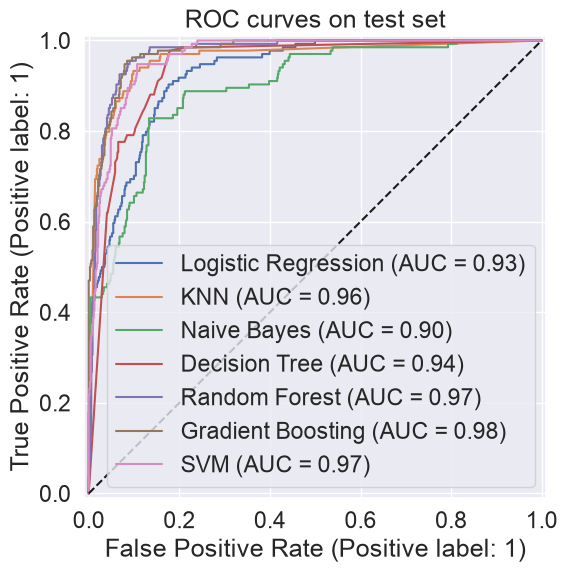

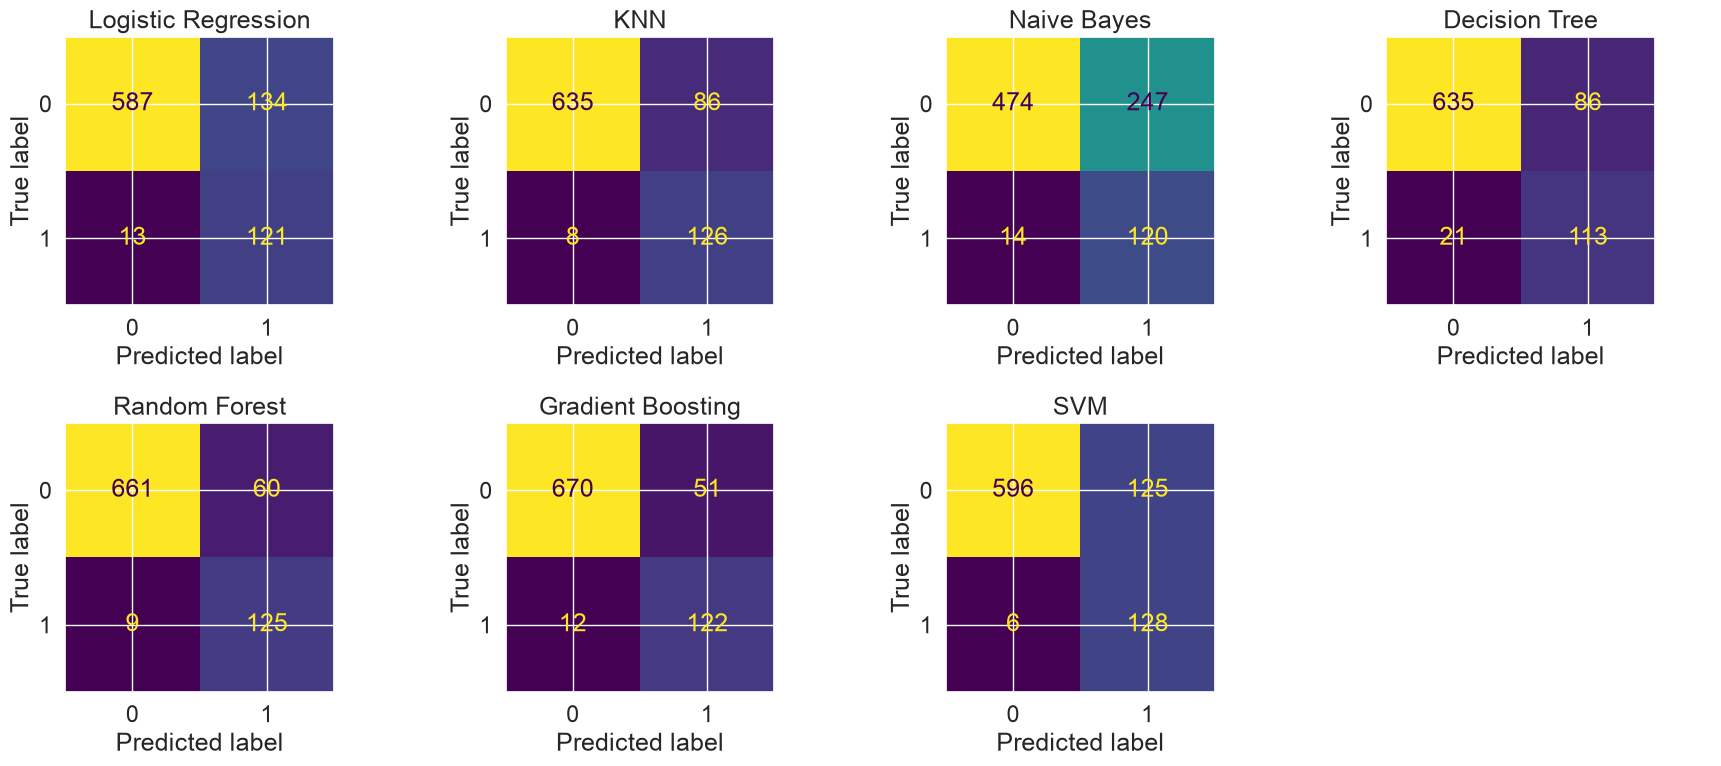

In [481]:
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(8, 6))
for name, m in best_models.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], 'k--')
plt.title('ROC curves on test set')
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, (name, m) in zip(axes.flat, best_models.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, ax=ax, colorbar=False)
    ax.set_title(name)
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

## Feature importance
The model sits inside the pipeline, so it is reached with `named_steps['model']`. `X_test` is passed in raw because the pipeline does its own scaling.

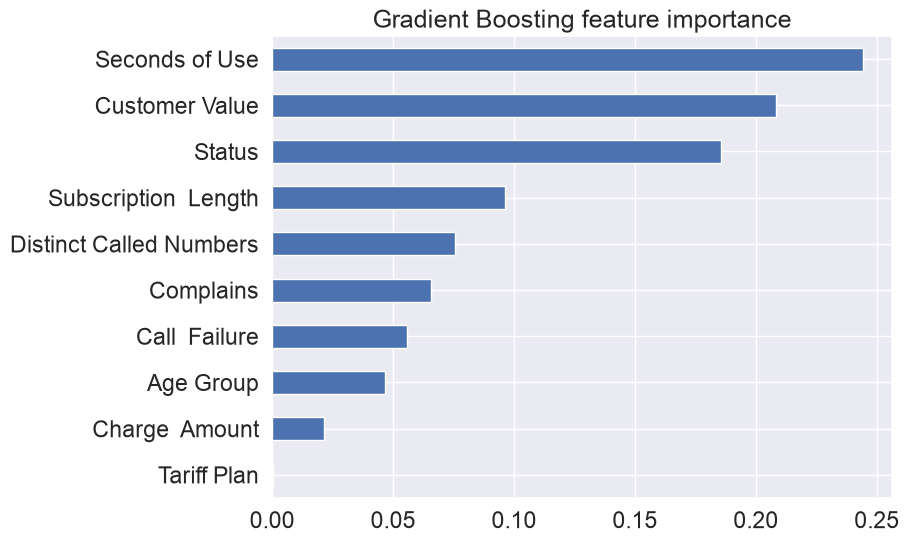

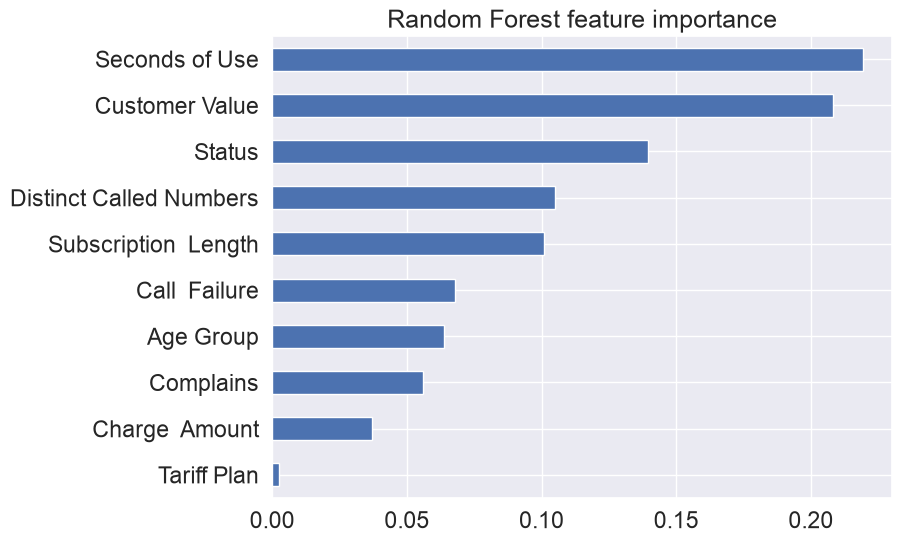

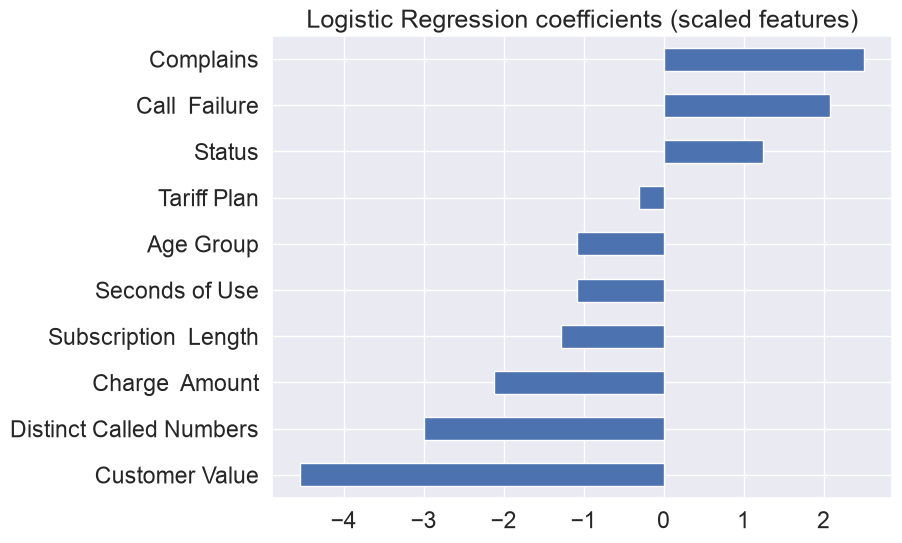

In [482]:
gb = best_models['Gradient Boosting'].named_steps['model']
pd.Series(gb.feature_importances_, index=X_train.columns).sort_values().plot(kind='barh', figsize=(8, 6))
plt.title('Gradient Boosting feature importance')
plt.show()

rf = best_models['Random Forest'].named_steps['model']
pd.Series(rf.feature_importances_, index=X_train.columns).sort_values().plot(kind='barh', figsize=(8, 6))
plt.title('Random Forest feature importance')
plt.show()

lr = best_models['Logistic Regression'].named_steps['model']
pd.Series(lr.coef_[0], index=X_train.columns).sort_values().plot(kind='barh', figsize=(8, 6))
plt.title('Logistic Regression coefficients (scaled features)')
plt.show()

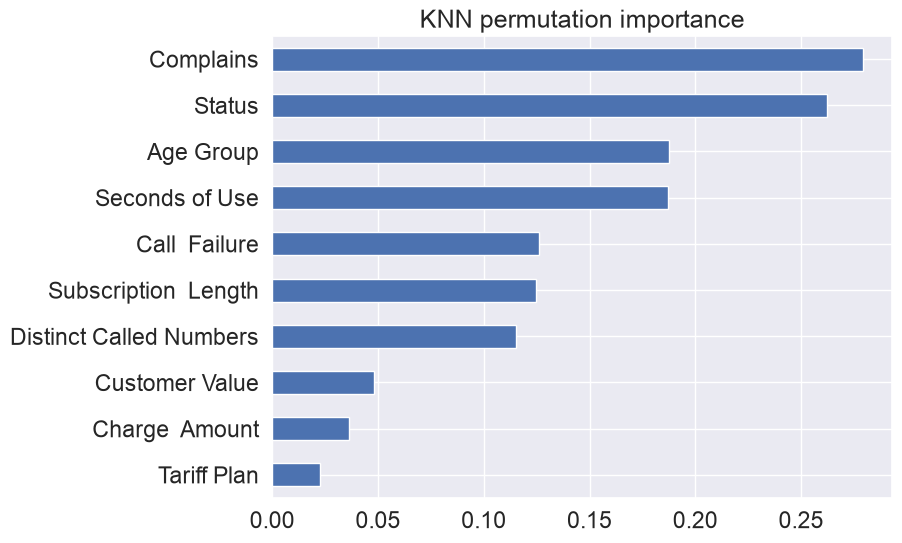

In [483]:
from sklearn.inspection import permutation_importance

r = permutation_importance(best_models['KNN'], X_test, y_test,
                           scoring='average_precision', n_repeats=10, random_state=42)
pd.Series(r.importances_mean, index=X_test.columns).sort_values().plot(kind='barh', figsize=(8, 6))
plt.title('KNN permutation importance')
plt.show()

## Final model: save and predict for a new customer
The saved file contains SMOTE, the scaler and the model together, so it takes raw customer values.

In [484]:
import joblib

best_name = results_df['Test PR-AUC'].idxmax()
final_model = best_models[best_name]
print("Final model:", best_name)

joblib.dump(final_model, 'churn_model.joblib')

# predicting for a "new" customer: raw values, same columns as X
new_customer = X_test.iloc[[0]]
print("Churn probability:", final_model.predict_proba(new_customer)[:, 1][0].round(3))

Final model: Gradient Boosting
Churn probability: 0.234
